In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import json
import seaborn
from scipy import ndimage
import matplotlib.lines as mlines
import scipy.sparse as sp

from Components.Solver.optimizer_fbrs import fbrs
from Components.ParameterInterface import DimensionlessParameterInterface
from Components.Model import IrrigationSchedulingModel
from Components.Controllers import TimeVaryingCost_LQRc_RHG
from Components.Model import IrrigationSchedulingCostLinearYield

In [4]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

# First try

## Build Data

In [4]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [5]:
# Infinite Horizon Welfare
directory = 'run_data/two_wells_analysis/infinite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        #print(param_data['controller']['time_horizon'])
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    data['infinite welfare'][well_distance] = result_data['inputs']

In [6]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['finite welfare'].keys():
        data['finite welfare'][well_distance] = {}
    data['finite welfare'][well_distance][horizon] = result_data['inputs']

In [7]:
# RHG
directory = 'run_data/two_wells_analysis/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['RHG'].keys():
        data['RHG'][well_distance] = {}
    data['RHG'][well_distance][horizon] = result_data['inputs']

## Display data

In [8]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [9]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

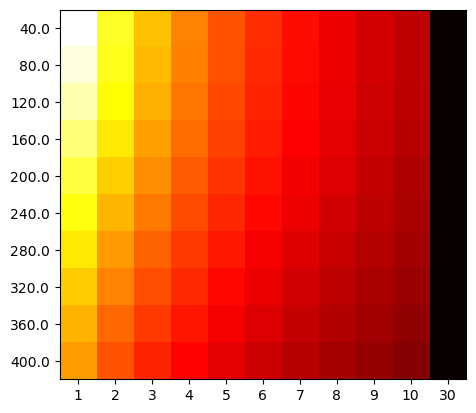

In [10]:
fig, ax = plt.subplots(1,1)
ax.imshow(finite_infinite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

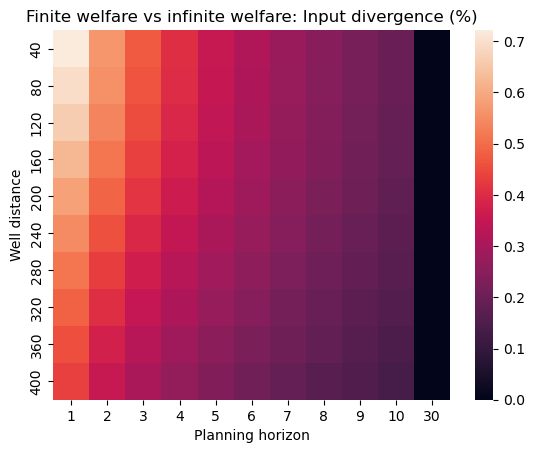

In [25]:
seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [31]:
finite_infinite_divergence[0][0]*100

np.float64(0.721583205764773)

In [27]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

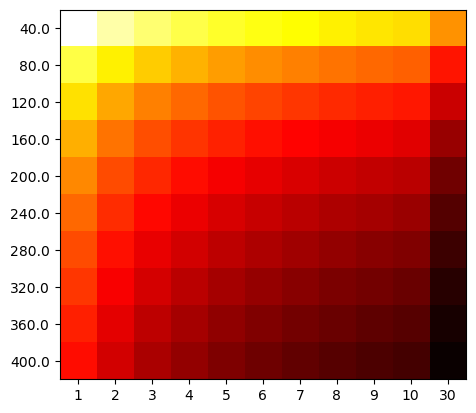

In [33]:
fig, ax = plt.subplots(1,1)
ax.imshow(RHG_infinite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

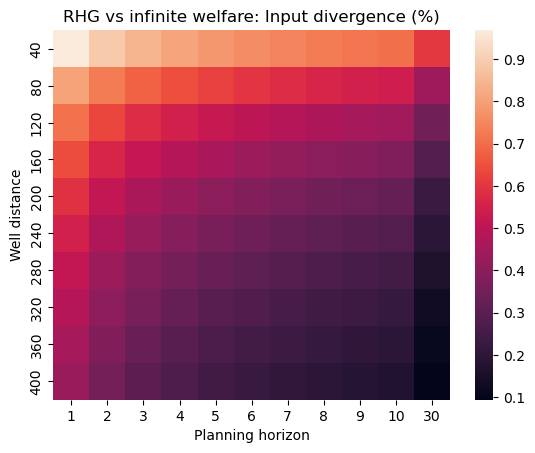

In [28]:
seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [34]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(0.9688086149467177), np.float64(0.09418218254953342))

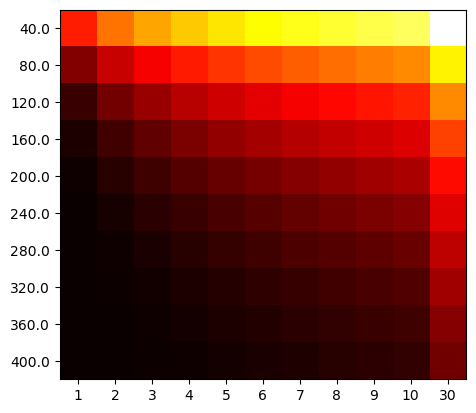

In [35]:
fig, ax = plt.subplots(1,1)
ax.imshow(RHG_finite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

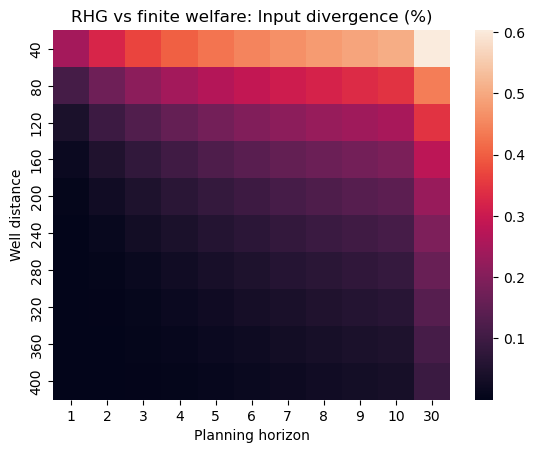

In [30]:
seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [36]:
RHG_finite_divergence.max()*100, RHG_finite_divergence.min()*100

(np.float64(0.6034687381394516), np.float64(2.802389591835921e-06))

In [37]:
RHG_infinite_divergence[0][10]

np.float64(0.006034687381394515)

Divergence between close and far wells

In [38]:
input_distances = np.linalg.norm(
    data['RHG'][400][30] - data['RHG'][40][30],
    axis=0)
input_divergences = input_distances / np.linalg.norm(
    data['RHG'][400][30], axis=0)
input_divergences.sum()/input_divergences.shape[0]

np.float64(0.005298572475028753)

# Smaller conductivity and new quadratic cost

## Build Data

In [5]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [6]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_low_k_c/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_redefinition_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['finite welfare'].keys():
        data['finite welfare'][well_distance] = {}
    data['finite welfare'][well_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for well_distance in data['finite welfare'].keys():
    data['infinite welfare'][well_distance] = data['finite welfare'][well_distance][30]

In [7]:
# RHG
directory = 'run_data/two_wells_analysis_low_k_c/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_redefinition_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['RHG'].keys():
        data['RHG'][well_distance] = {}
    data['RHG'][well_distance][horizon] = result_data['inputs']

## Display data

In [8]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [9]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

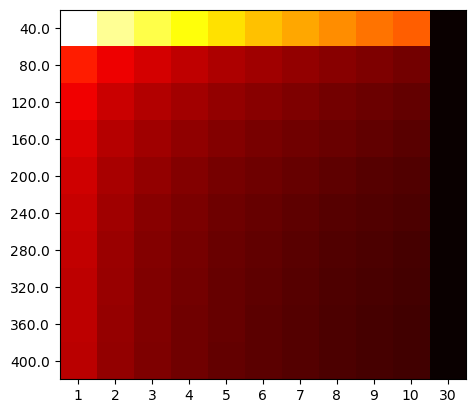

In [10]:
fig, ax = plt.subplots(1,1)
ax.imshow(finite_infinite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

In [19]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(1.3016056163788996), np.float64(0.5316697637680221))

In [12]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

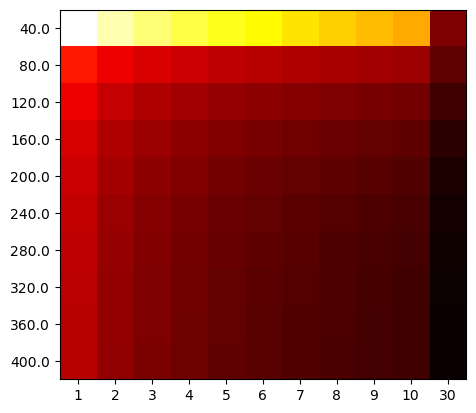

In [13]:
fig, ax = plt.subplots(1,1)
ax.imshow(RHG_infinite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

In [14]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(1.3242035146631466), np.float64(0.00207879885499906))

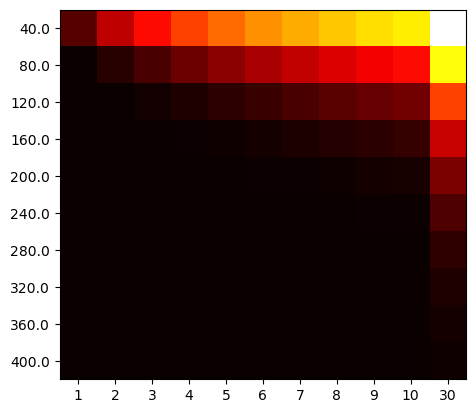

In [15]:
fig, ax = plt.subplots(1,1)
ax.imshow(RHG_finite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

In [16]:
RHG_finite_divergence.max()*100, RHG_finite_divergence.min()*100

(np.float64(0.230276582569527), np.float64(0.0))

In [17]:
RHG_infinite_divergence[0][10]

np.float64(0.00230276582569527)

Divergence between close and far wells

In [18]:
input_distances = np.linalg.norm(
    data['RHG'][400][30] - data['RHG'][40][30],
    axis=0)
input_divergences = input_distances / np.linalg.norm(
    data['RHG'][400][30], axis=0)
input_divergences.sum()/input_divergences.shape[0]

np.float64(0.01581628922277281)

# Dimensionless system

## Build Data

In [2]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [6]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['finite welfare'].keys():
        data['finite welfare'][well_distance] = {}
    data['finite welfare'][well_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for well_distance in data['finite welfare'].keys():
    data['infinite welfare'][well_distance] = data['finite welfare'][well_distance][30]

In [7]:
# RHG
directory = 'run_data/two_wells_analysis_dimless/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['RHG'].keys():
        data['RHG'][well_distance] = {}
    data['RHG'][well_distance][horizon] = result_data['inputs']

## Display data

In [8]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [9]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

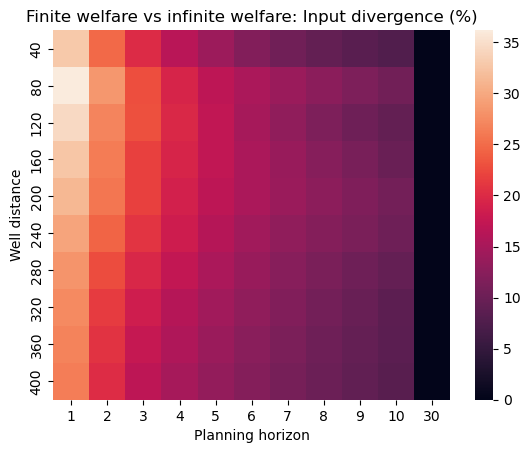

In [19]:
seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [11]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(32.841196820056425), np.float64(36.19327444608803))

In [12]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

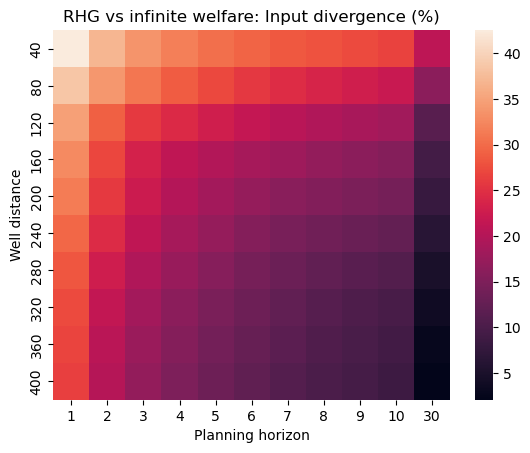

In [20]:
seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [14]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(42.52772699810686), np.float64(2.0878663519057308))

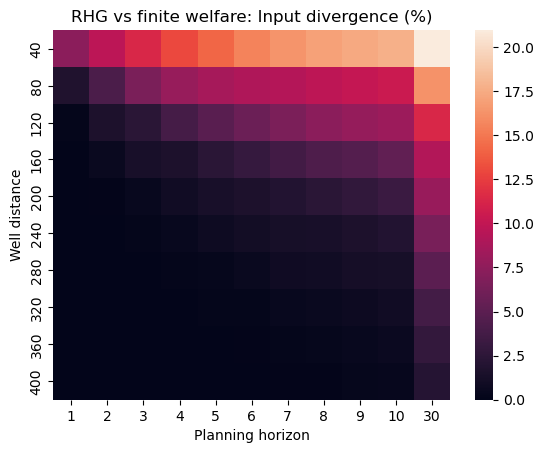

In [21]:
seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [16]:
RHG_finite_divergence.max()*100, RHG_finite_divergence.min()*100

(np.float64(20.956305327377336), np.float64(0.0))

In [17]:
RHG_infinite_divergence[0][10]

np.float64(0.20956305327377336)

Divergence between close and far wells

In [18]:
input_distances = np.linalg.norm(
    data['RHG'][400][30] - data['RHG'][40][30],
    axis=0)
input_divergences = input_distances / np.linalg.norm(
    data['RHG'][400][30], axis=0)
input_divergences.sum()/input_divergences.shape[0]

np.float64(0.1707265614397406)

# Dimensionless system -- Longer simulation

## Build Data

In [132]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [133]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['finite welfare'].keys():
        data['finite welfare'][well_distance] = {}
    data['finite welfare'][well_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for well_distance in data['finite welfare'].keys():
    data['infinite welfare'][well_distance] = data['finite welfare'][well_distance][30]

In [134]:
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['RHG'].keys():
        data['RHG'][well_distance] = {}
    data['RHG'][well_distance][horizon] = result_data['inputs']

## Display data

In [135]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [136]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

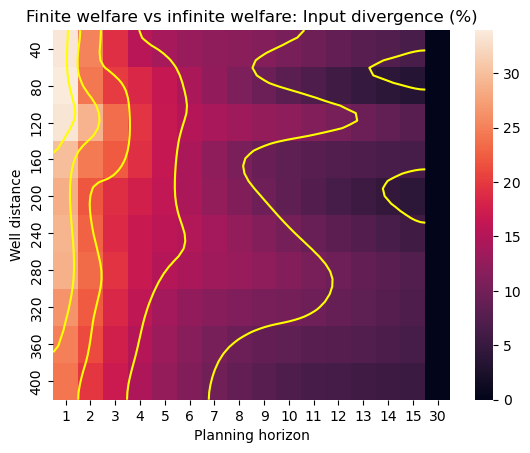

In [137]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, finite_infinite_divergence[:,:-1].shape[1], finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, finite_infinite_divergence[:,:-1].shape[0], finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [138]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(33.49957728372858), np.float64(33.96459409741891))

In [139]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

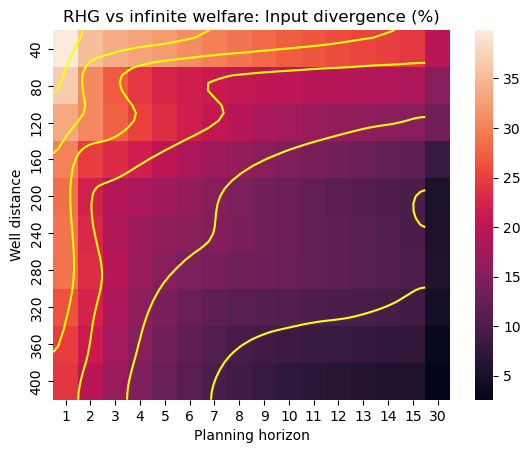

In [140]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_divergence[:,:-1].shape[1], RHG_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_divergence[:,:-1].shape[0], RHG_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [141]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(39.88080124356269), np.float64(2.584192949220764))

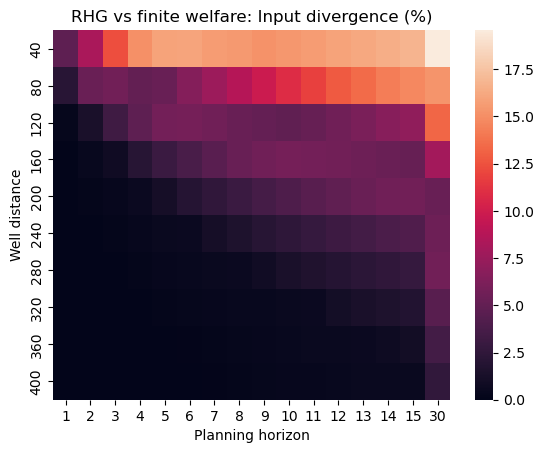

In [191]:
fig, ax = plt.subplots()

# smooth_scale = 5
# z = ndimage.zoom(RHG_finite_divergence[:,:-1]*100, smooth_scale)
# cntr = ax.contour(np.linspace(0, RHG_finite_divergence[:,:-1].shape[1], RHG_finite_divergence[:,:-1].shape[1] * smooth_scale),
#                   np.linspace(0, RHG_finite_divergence[:,:-1].shape[0], RHG_finite_divergence[:,:-1].shape[0] * smooth_scale),
#                   z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [143]:
# RHG input divergence
RHG_finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['RHG'][distance][30] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['RHG'][distance][30], axis=0)
        RHG_finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

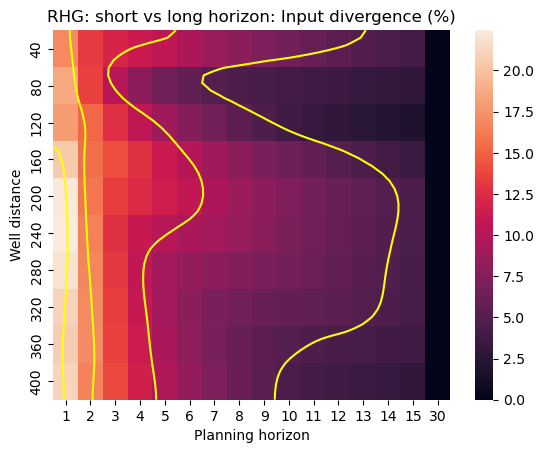

In [144]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[1], RHG_finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[0], RHG_finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG: short vs long horizon: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

### Heads and pumping rates volume comparison

In [145]:
data_d = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}
data_q = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [146]:
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data_d['RHG'].keys():
        data_d['RHG'][well_distance] = {}
        data_q['RHG'][well_distance] = {}
    data_d['RHG'][well_distance][horizon] = result_data['h_wells'][:,-10:].mean(axis=1)
    data_q['RHG'][well_distance][horizon] = result_data['q_rates'][:,-10:].mean(axis=1)

In [147]:
# Order keys/axis
distances = np.sort(list(data_d['RHG'].keys()))
horizons = np.sort(list(data_d['RHG'][distances[0]].keys()))

In [148]:
# Depth
depth_p1 = np.zeros((len(distances), len(horizons)))
depth_p2 = np.zeros((len(distances), len(horizons)))
pumping_p1 = np.zeros((len(distances), len(horizons)))
pumping_p2 = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        depth_p1[d][h] = 10 - data_d['RHG'][distance][horizon][0]
        depth_p2[d][h] = 10 - data_d['RHG'][distance][horizon][1]
        pumping_p1[d][h] = - data_q['RHG'][distance][horizon][0]
        pumping_p2[d][h] = - data_q['RHG'][distance][horizon][1]

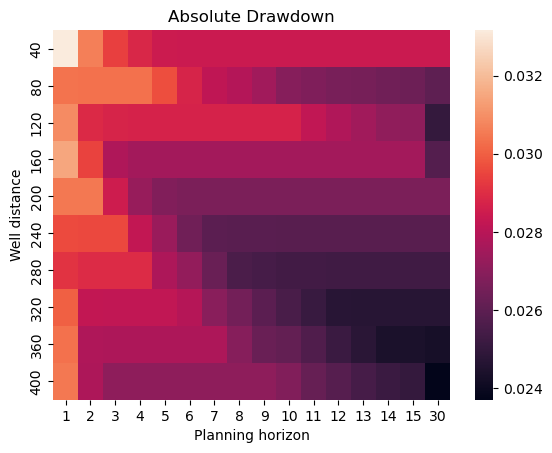

In [149]:
seaborn.heatmap(depth_p1,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("Absolute Drawdown")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

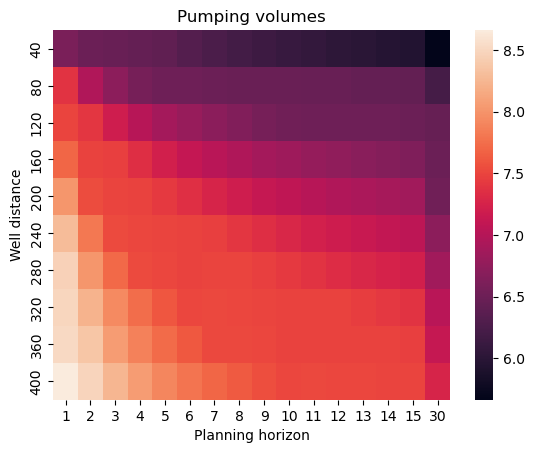

In [150]:
seaborn.heatmap(pumping_p1,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("Pumping volumes")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [151]:
data_q['RHG'][40][1]

array([-6.59159096, -6.656109  ])

In [152]:
pumping_p1[0,0]

np.float64(6.5915909566554)

### Evolution at reference variables

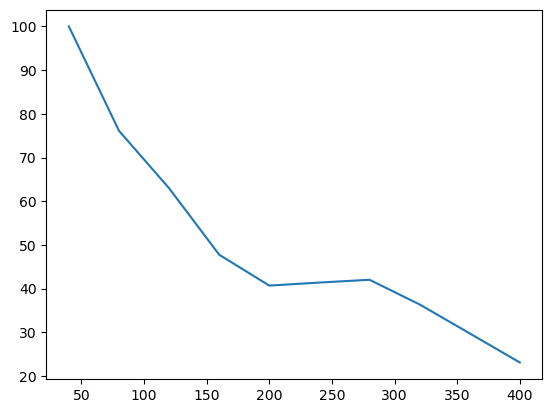

In [153]:
plt.plot(distances.astype(int), RHG_infinite_divergence[:,14]*100/RHG_infinite_divergence[0,14])

The "rebound" is there because when we compare to infinite welfare, we don't only decrease coupling as distance increases. There are less quantifiable  effects on the horizon necessary to predict one's own effect on their wells.

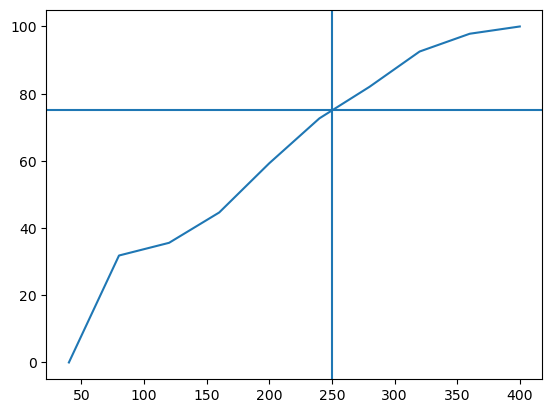

In [154]:
plt.plot(distances.astype(int), (pumping_p1[:,14]-pumping_p1[0,14])*100/(pumping_p1[-1,14]-pumping_p1[0,14]))
plt.axvline(250, 0, 100)
plt.axhline(75, 0, 400)

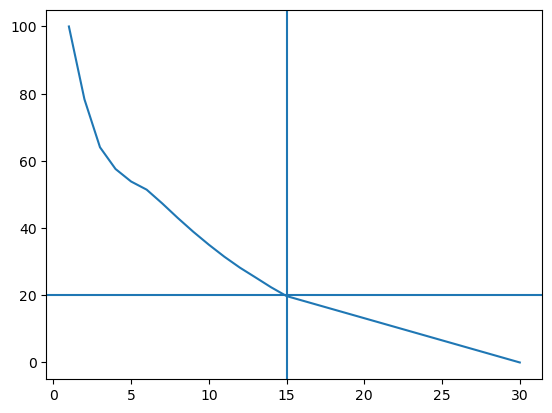

In [155]:
plt.plot(horizons, finite_infinite_divergence[5,:]*100/finite_infinite_divergence[5,0])
plt.axvline(15, 0, 100)
plt.axhline(20, 0, 400)

In fact, here it is the same: when increasing horizon, we make apparent effects of coupling AND effect of oneself on its own well.

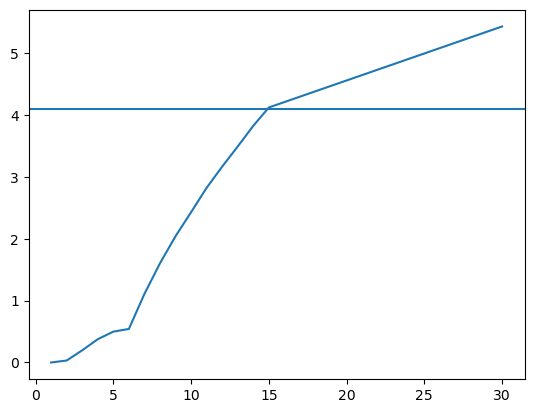

In [156]:
plt.plot(horizons, RHG_finite_divergence[5,:]*100)
plt.axhline(4.1, 0,30)

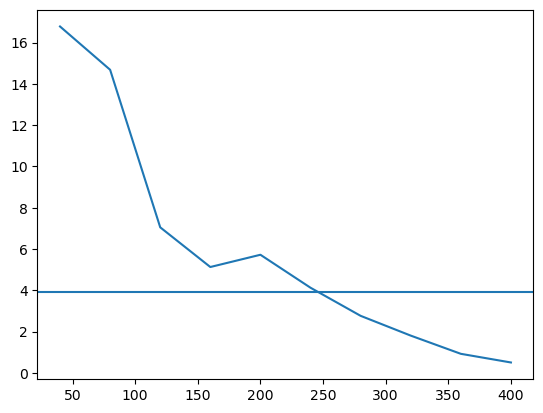

In [157]:
plt.plot(distances.astype(int), RHG_finite_divergence[:,14]*100)
plt.axhline(3.9, 0,400)

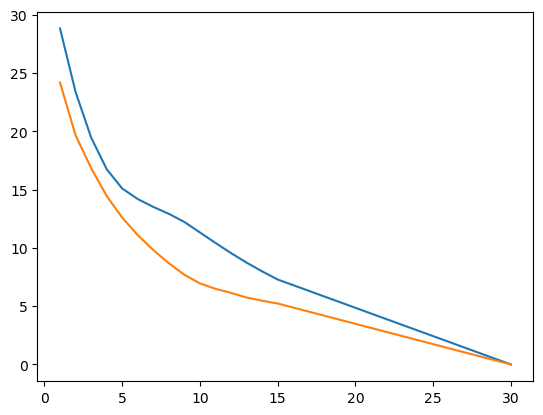

In [158]:
plt.plot(horizons, (finite_infinite_divergence[6,:])*100)
plt.plot(horizons, (finite_infinite_divergence[-1,:])*100)

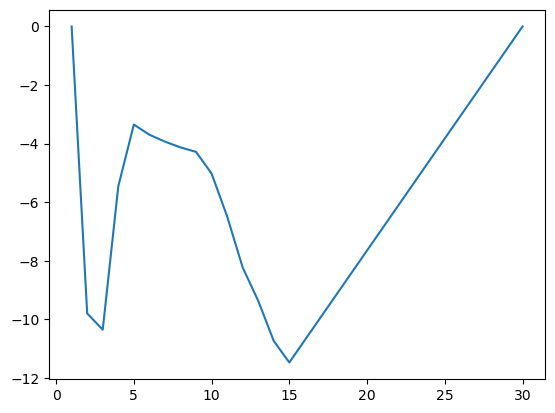

In [159]:
k=1
plt.plot(horizons, ((finite_infinite_divergence[k,:]/finite_infinite_divergence[k,0])-(finite_infinite_divergence[-1,:]/finite_infinite_divergence[-1,0]))*100)

In [160]:
# Welfare input decrease
welfare_decrease = np.zeros((len(distances), len(horizons)-2))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons[:-2]):
        input_distances = np.linalg.norm(
            data['finite welfare'][distance][horizon+1] - data['finite welfare'][distance][horizon],
            axis=0)
        # input_divergences = input_distances / np.linalg.norm(
        #     data['finite welfare'][distance][horizon+1], axis=0)
        welfare_decrease[d][h] = input_distances.sum()/input_distances.shape[0]

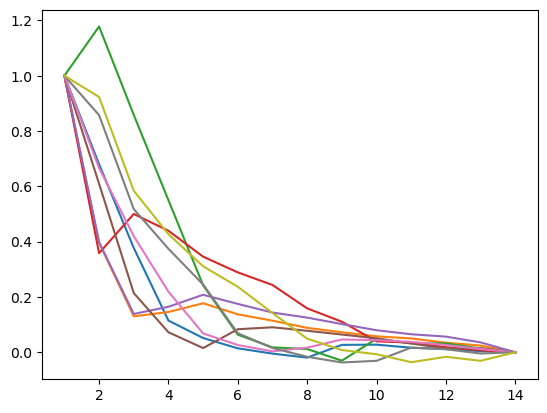

In [161]:
for k in range(9):
    plt.plot(horizons[:-2], (welfare_decrease[k,:]-welfare_decrease[k,-1])/(welfare_decrease[k,0]-welfare_decrease[k,-1]))

# Dimensionless system -- Longer simulation + Head constraint

## Build Data

In [29]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [30]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_cstr/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['finite welfare'].keys():
        data['finite welfare'][well_distance] = {}
    data['finite welfare'][well_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for well_distance in data['finite welfare'].keys():
    data['infinite welfare'][well_distance] = data['finite welfare'][well_distance][30]

In [31]:
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_cstr/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['RHG'].keys():
        data['RHG'][well_distance] = {}
    data['RHG'][well_distance][horizon] = result_data['inputs']

## Display data

In [32]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [33]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

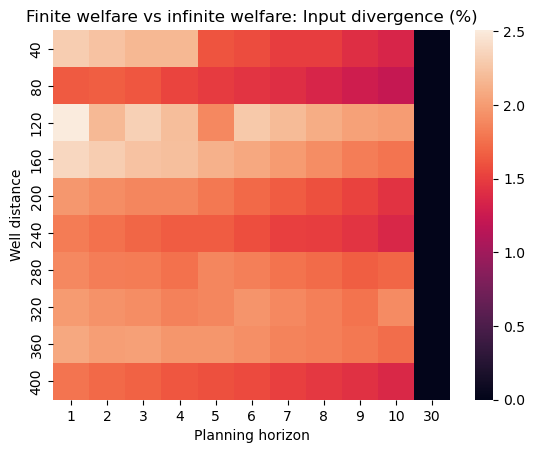

In [34]:
seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [35]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(2.307890843073369), np.float64(1.6441395211324732))

In [36]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

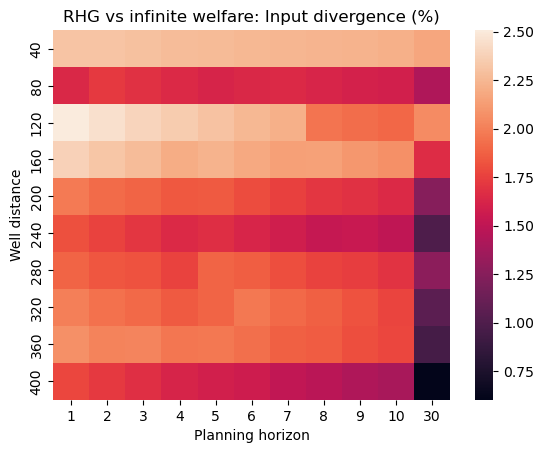

In [37]:
seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [38]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(2.307890845726442), np.float64(0.6031713057877693))

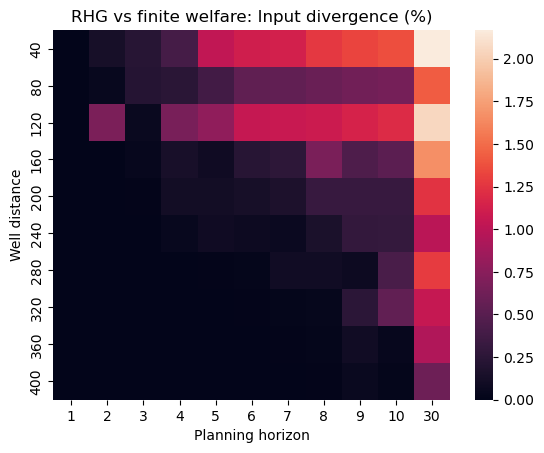

In [39]:
seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

# Dimensionless system -- Longer simulation + Cost inversion

## Build Data

In [111]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [112]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_high_sell/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['finite welfare'].keys():
        data['finite welfare'][well_distance] = {}
    data['finite welfare'][well_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for well_distance in data['finite welfare'].keys():
    data['infinite welfare'][well_distance] = data['finite welfare'][well_distance][30]

In [113]:
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_high_sell/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['RHG'].keys():
        data['RHG'][well_distance] = {}
    data['RHG'][well_distance][horizon] = result_data['inputs']

## Display data

In [114]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [115]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

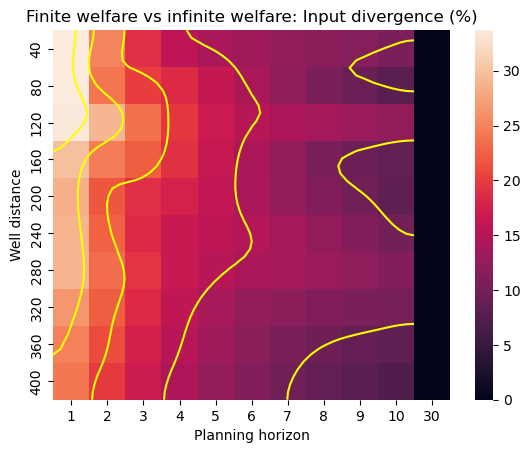

In [116]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, finite_infinite_divergence[:,:-1].shape[1], finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, finite_infinite_divergence[:,:-1].shape[0], finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [117]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(33.70369738973457), np.float64(33.66629305646751))

In [118]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

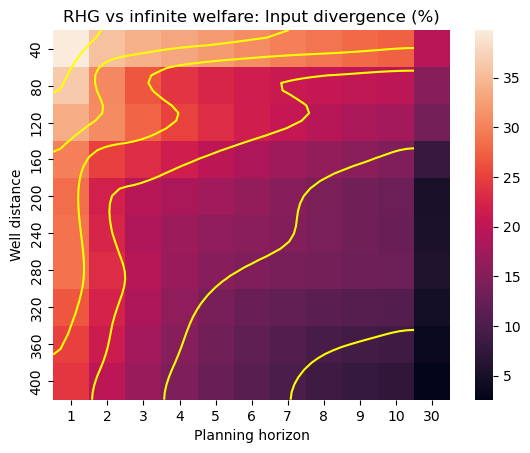

In [119]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_divergence[:,:-1].shape[1], RHG_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_divergence[:,:-1].shape[0], RHG_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [120]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(39.78208827603365), np.float64(2.584655928997807))

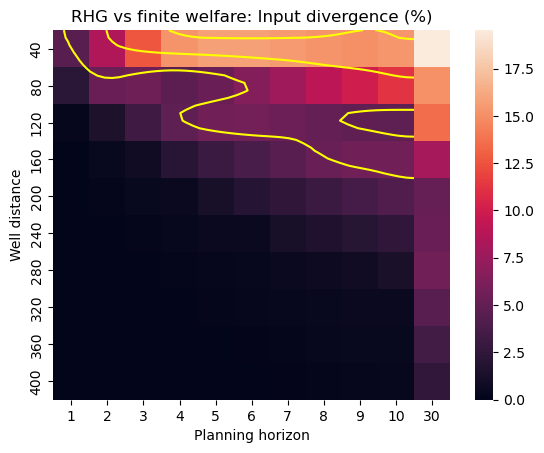

In [121]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_divergence[:,:-1].shape[1], RHG_finite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_divergence[:,:-1].shape[0], RHG_finite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [122]:
# RHG input divergence
RHG_finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['RHG'][distance][30] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['RHG'][distance][30], axis=0)
        RHG_finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

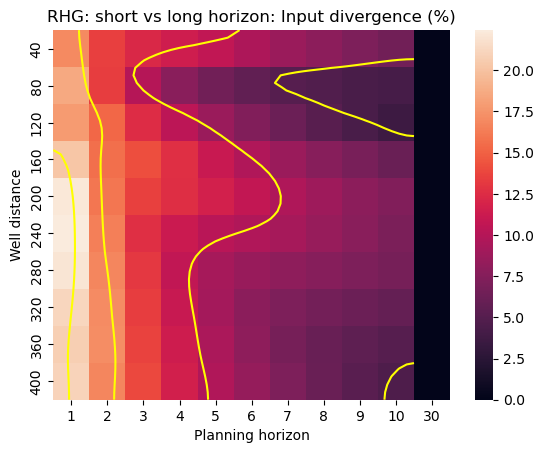

In [123]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[1], RHG_finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[0], RHG_finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG: short vs long horizon: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

# Article figures

KeyError: 40

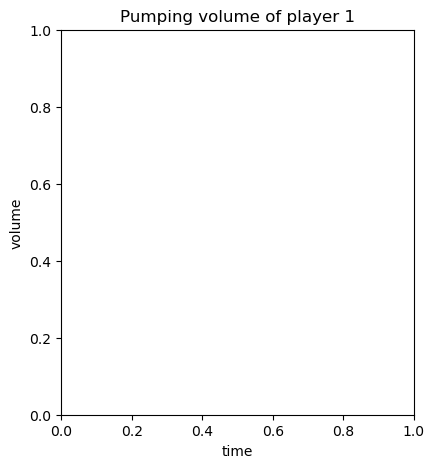

In [44]:
fig = plt.figure(figsize=(10,5))
ax = None

# Player 1
ax = fig.add_subplot(1, 2, 1, sharey=ax)
ttl = f"Pumping volume of player 1"
ax.set_title(ttl)
ax.set_ylabel("volume")
ax.set_xlabel("time")
ax.plot(-data['RHG'][40][1][:4,:].sum(axis=0), "red", label='RHG')
plt.plot(-data['finite welfare'][40][30][:4,:].sum(axis=0), "orange", label='welfare')

# Player 2
ax = fig.add_subplot(1, 2, 2, sharey=ax)
ttl = f"Pumping volume of player 2"
ax.set_title(ttl)
ax.set_xlabel("time")
ax.plot(-data['RHG'][40][1][4:,:].sum(axis=0), "red", label='RHG')
plt.plot(-data['finite welfare'][40][30][4:,:].sum(axis=0), "orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

plt.plot()

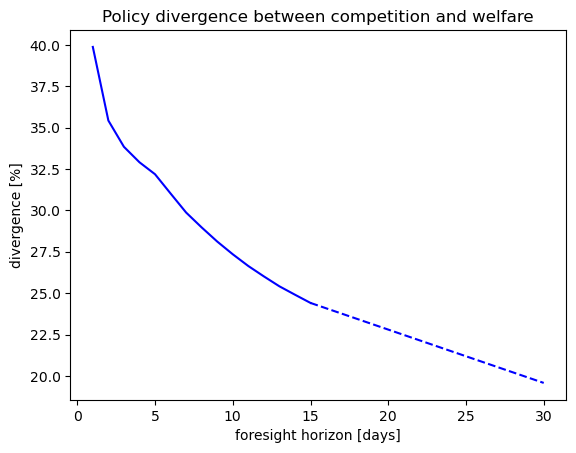

In [174]:
fig, ax = plt.subplots()
ax.plot(horizons[:-1], RHG_infinite_divergence[0,:-1]*100, "b")
ax.plot(horizons[-2:], RHG_infinite_divergence[0,-2:]*100, "b--")

ax.set_title("Policy divergence between competition and welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel("foresight horizon [days]")

plt.show()


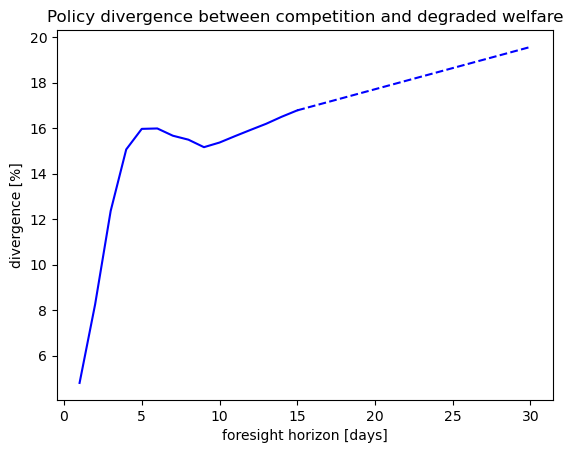

In [186]:
fig, ax = plt.subplots()
# ax.plot(horizons[:-1], RHG_finite_divergence.mean(axis=0)[:-1]*100, "b")
# ax.plot(horizons[-2:], RHG_finite_divergence.mean(axis=0)[-2:]*100, "b--")
ax.plot(horizons[:-1], RHG_finite_divergence[0,:-1]*100, "b")
ax.plot(horizons[-2:], RHG_finite_divergence[0,-2:]*100, "b--")

ax.set_title("Policy divergence between competition and degraded welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel("foresight horizon [days]")

plt.show()

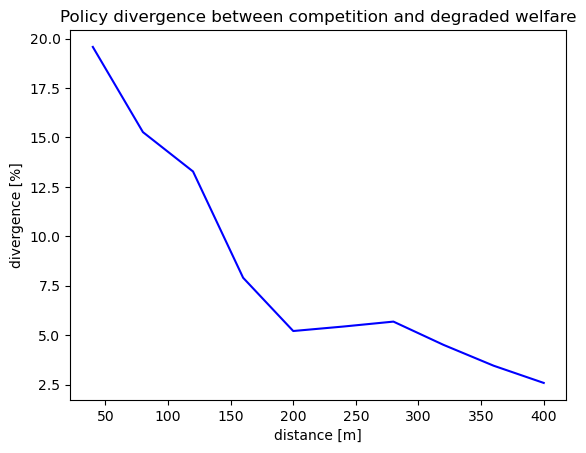

In [188]:
fig, ax = plt.subplots()
plt.plot(distances.astype(int), RHG_infinite_divergence[:,-1]*100, "b")

ax.set_title("Policy divergence between competition and degraded welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel("distance [m]")

plt.show()

# Dimensionless system -- Longer simulation + Cost inversion + Avoid borders

## Build Data

In [30]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [31]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_high_sell_avoid_borders/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data['finite welfare'].keys():
        data['finite welfare'][rel_distance] = {}
    data['finite welfare'][rel_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for rel_distance in data['finite welfare'].keys():
    data['infinite welfare'][rel_distance] = data['finite welfare'][rel_distance][30]

In [32]:
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_high_sell_avoid_borders/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data['RHG'].keys():
        data['RHG'][rel_distance] = {}
    data['RHG'][rel_distance][horizon] = result_data['inputs']

## Display data

In [33]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [34]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

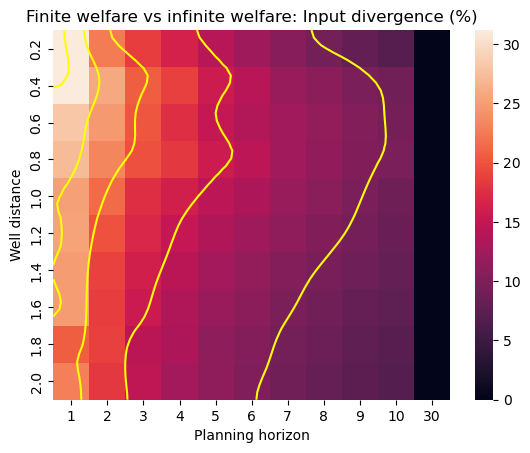

In [35]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, finite_infinite_divergence[:,:-1].shape[1], finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, finite_infinite_divergence[:,:-1].shape[0], finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [9]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(33.20487704221563), np.float64(33.66629305646751))

In [37]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

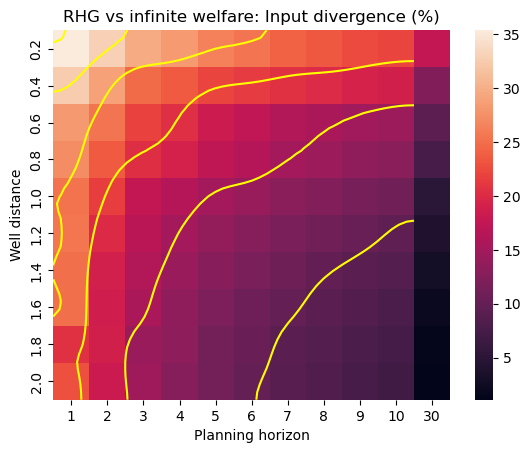

In [40]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_divergence[:,:-1].shape[1], RHG_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_divergence[:,:-1].shape[0], RHG_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [12]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(22.79051371629343), np.float64(2.584655928997807))

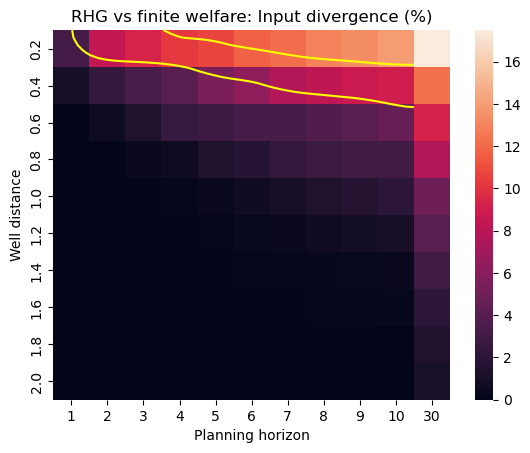

In [43]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_divergence[:,:-1].shape[1], RHG_finite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_divergence[:,:-1].shape[0], RHG_finite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [14]:
# RHG input divergence
RHG_finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['RHG'][distance][30] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['RHG'][distance][30], axis=0)
        RHG_finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

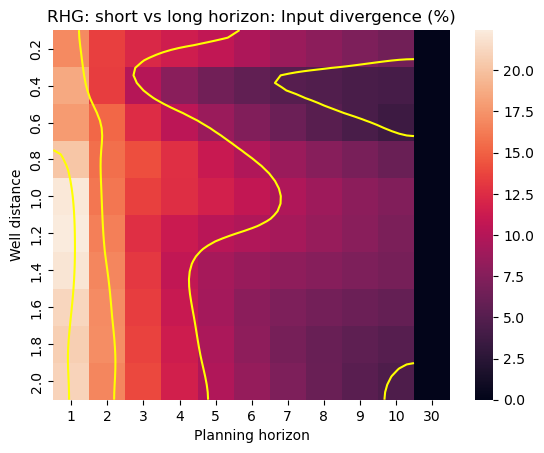

In [42]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[1], RHG_finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[0], RHG_finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("RHG: short vs long horizon: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

## Article figures

[]

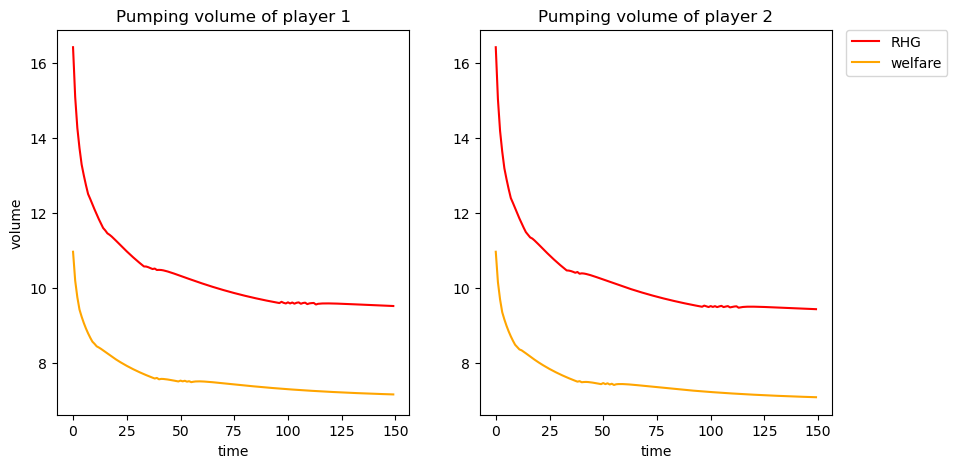

In [45]:
fig = plt.figure(figsize=(10,5))
ax = None

# Player 1
ax = fig.add_subplot(1, 2, 1, sharey=ax)
ttl = f"Pumping volume of player 1"
ax.set_title(ttl)
ax.set_ylabel("volume")
ax.set_xlabel("time")
ax.plot(-data['RHG'][0.2][1][:4,:].sum(axis=0), "red", label='RHG')
plt.plot(-data['finite welfare'][0.2][30][:4,:].sum(axis=0), "orange", label='welfare')

# Player 2
ax = fig.add_subplot(1, 2, 2, sharey=ax)
ttl = f"Pumping volume of player 2"
ax.set_title(ttl)
ax.set_xlabel("time")
ax.plot(-data['RHG'][0.2][1][4:,:].sum(axis=0), "red", label='RHG')
plt.plot(-data['finite welfare'][0.2][30][4:,:].sum(axis=0), "orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

plt.plot()

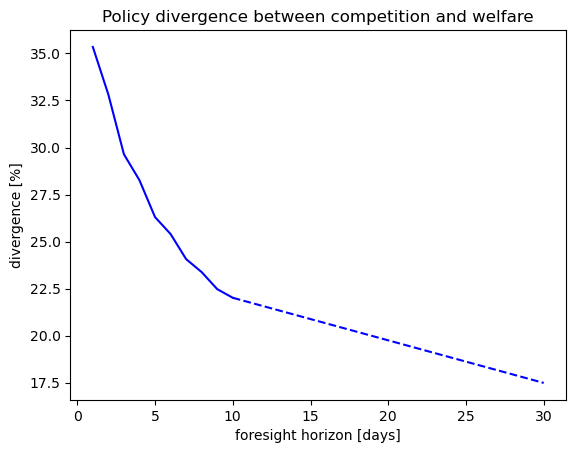

In [46]:
fig, ax = plt.subplots()
ax.plot(horizons[:-1], RHG_infinite_divergence[0,:-1]*100, "b")
ax.plot(horizons[-2:], RHG_infinite_divergence[0,-2:]*100, "b--")

ax.set_title("Policy divergence between competition and welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel("foresight horizon [days]")

plt.show()


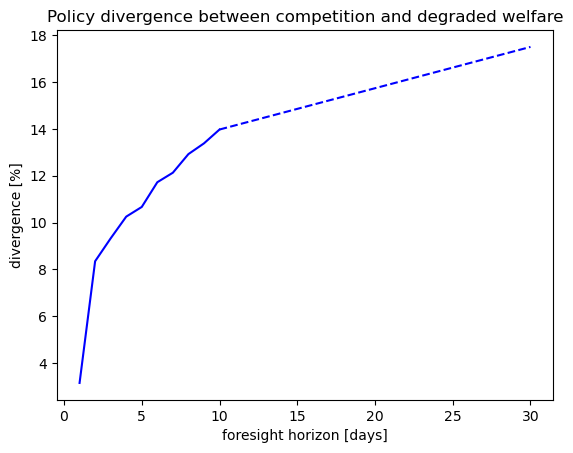

In [47]:
fig, ax = plt.subplots()
# ax.plot(horizons[:-1], RHG_finite_divergence.mean(axis=0)[:-1]*100, "b")
# ax.plot(horizons[-2:], RHG_finite_divergence.mean(axis=0)[-2:]*100, "b--")
ax.plot(horizons[:-1], RHG_finite_divergence[0,:-1]*100, "b")
ax.plot(horizons[-2:], RHG_finite_divergence[0,-2:]*100, "b--")

ax.set_title("Policy divergence between competition and degraded welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel("foresight horizon [days]")

plt.show()

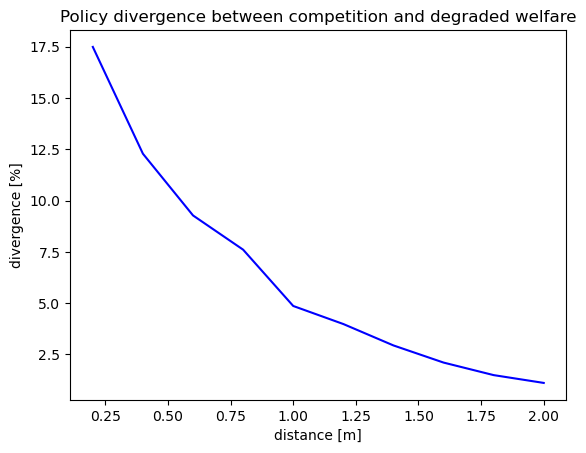

In [49]:
fig, ax = plt.subplots()
plt.plot(distances, RHG_infinite_divergence[:,-1]*100, "b")

ax.set_title("Policy divergence between competition and degraded welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel("distance [m]")

plt.show()

# Dimensionless system -- Longer simulation + Cost inversion + Avoid borders + Longer R_p

## Build Data

In [3]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [4]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_high_sell_avoid_borders/longer_Rp/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data['finite welfare'].keys():
        data['finite welfare'][rel_distance] = {}
    data['finite welfare'][rel_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for rel_distance in data['finite welfare'].keys():
    data['infinite welfare'][rel_distance] = data['finite welfare'][rel_distance][30]

In [5]:
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_high_sell_avoid_borders/longer_Rp/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data['RHG'].keys():
        data['RHG'][rel_distance] = {}
    data['RHG'][rel_distance][horizon] = result_data['inputs']

## Display data

In [6]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [7]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

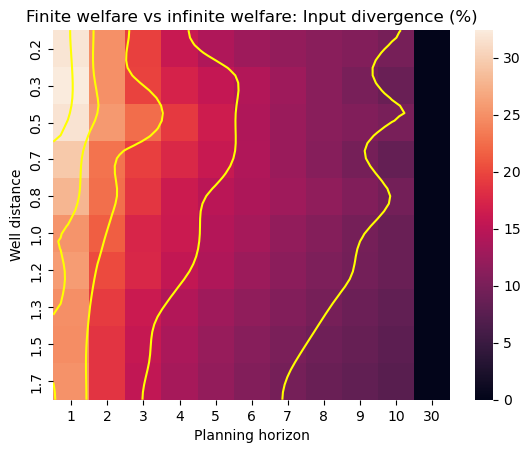

In [8]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, finite_infinite_divergence[:,:-1].shape[1], finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, finite_infinite_divergence[:,:-1].shape[0], finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [9]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(31.786397886077594), np.float64(32.41188358867696))

In [10]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

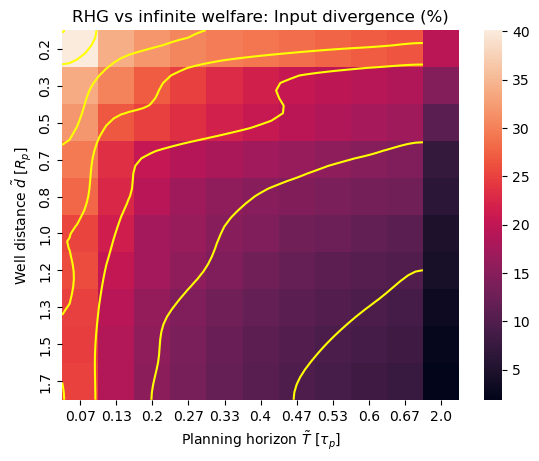

In [11]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_divergence[:,:-1].shape[1], RHG_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_divergence[:,:-1].shape[0], RHG_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

#plt.savefig('../../Paper/figures/AddFig1.svg', format='svg')
plt.show()

In [12]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(40.12991223356336), np.float64(1.876990643133217))

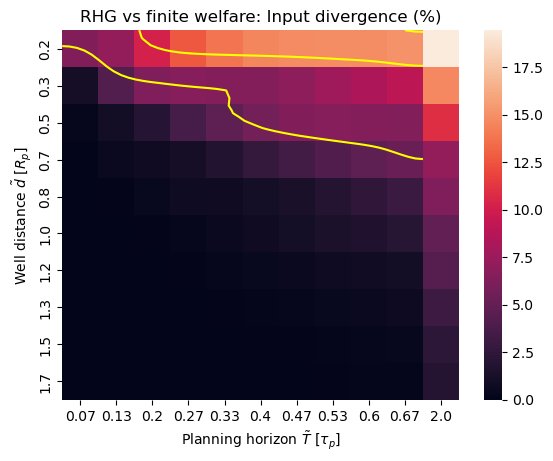

In [13]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_divergence[:,:-1].shape[1], RHG_finite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_divergence[:,:-1].shape[0], RHG_finite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

In [14]:
# RHG input divergence
RHG_finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['RHG'][distance][30] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['RHG'][distance][30], axis=0)
        RHG_finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

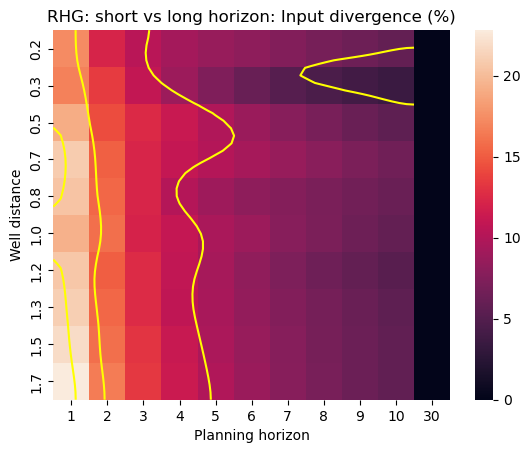

In [15]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[1], RHG_finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[0], RHG_finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("RHG: short vs long horizon: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

## Article figures

[]

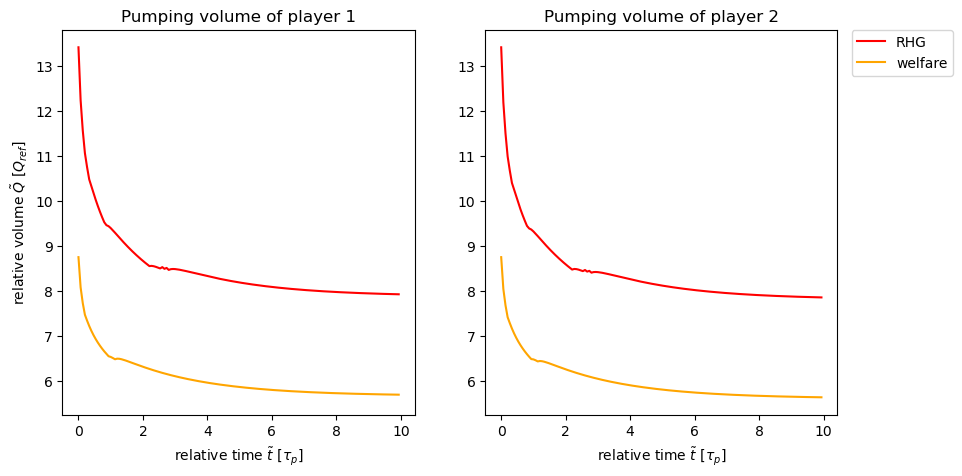

In [16]:
fig = plt.figure(figsize=(10,5))
ax = None
rel_times = np.arange(len(data['RHG'][distances[0]][1][:4,:].sum(axis=0)))/param_data['dimensions']['tau_p']

# Player 1
ax = fig.add_subplot(1, 2, 1, sharey=ax)
ttl = f"Pumping volume of player 1"
ax.set_title(ttl)
ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
ax.plot(rel_times, -data['RHG'][distances[0]][1][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], "red", label='RHG')
ax.plot(rel_times, -data['finite welfare'][distances[0]][30][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], "orange", label='welfare')

# Player 2
ax = fig.add_subplot(1, 2, 2, sharey=ax)
ttl = f"Pumping volume of player 2"
ax.set_title(ttl)
ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
ax.plot(rel_times, -data['RHG'][distances[0]][1][4:,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], "red", label='RHG')
ax.plot(rel_times, -data['finite welfare'][distances[0]][30][4:,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], "orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

plt.plot()

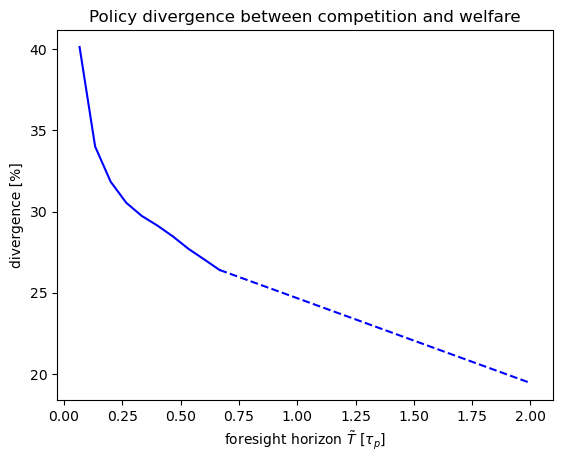

In [17]:
fig, ax = plt.subplots()
ax.plot(horizons[:-1]/param_data['dimensions']['tau_p'], RHG_infinite_divergence[0,:-1]*100, "b")
ax.plot(horizons[-2:]/param_data['dimensions']['tau_p'], RHG_infinite_divergence[0,-2:]*100, "b--")

ax.set_title("Policy divergence between competition and welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel(r"foresight horizon $\tilde T$ [$\tau_p$]")

plt.show()


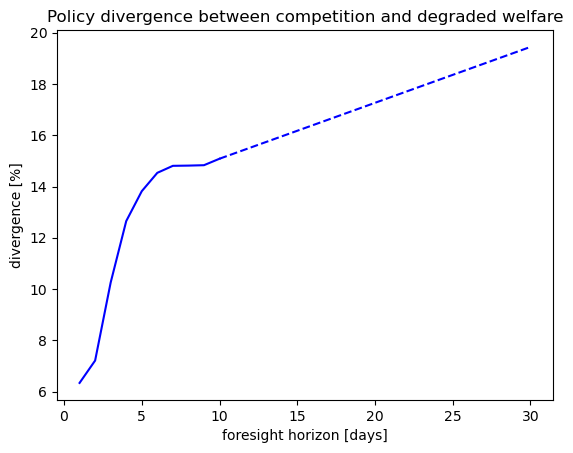

In [617]:
fig, ax = plt.subplots()
# ax.plot(horizons[:-1], RHG_finite_divergence.mean(axis=0)[:-1]*100, "b")
# ax.plot(horizons[-2:], RHG_finite_divergence.mean(axis=0)[-2:]*100, "b--")
ax.plot(horizons[:-1], RHG_finite_divergence[0,:-1]*100, "b")
ax.plot(horizons[-2:], RHG_finite_divergence[0,-2:]*100, "b--")

ax.set_title("Policy divergence between competition and degraded welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel("foresight horizon [days]")

plt.show()

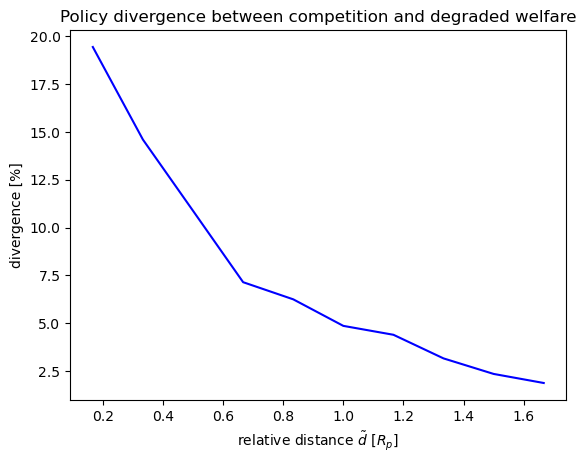

In [618]:
fig, ax = plt.subplots()
plt.plot(distances, RHG_infinite_divergence[:,-1]*100, "b")

ax.set_title("Policy divergence between competition and degraded welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel(r"relative distance $\tilde d$ [$R_p$]")

plt.show()

In [619]:
cost_data = {'total': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}, \
             'pumping': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}, \
                'yield': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}}

In [620]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_high_sell_avoid_borders/longer_Rp/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in cost_data['total']['finite welfare'].keys():
        cost_data['total']['finite welfare'][rel_distance] = {}
        cost_data['pumping']['finite welfare'][rel_distance] = {}
        cost_data['yield']['finite welfare'][rel_distance] = {}
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    # cost_heads = (result_data['h_wells'][:,1:] + result_data['h_wells'][:,:-1])/2
    cost_heads = result_data['h_wells'][:,:-1] 
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = - alpha * result_data['q_rates'][:,:-1]
    cost_data['total']['finite welfare'][rel_distance][horizon] = pumping_cost + yield_profit
    cost_data['pumping']['finite welfare'][rel_distance][horizon] = pumping_cost
    cost_data['yield']['finite welfare'][rel_distance][horizon] = yield_profit

# Infinite Horizon Welfare
for rel_distance in cost_data['total']['finite welfare'].keys():
    cost_data['total']['infinite welfare'][rel_distance] = cost_data['total']['finite welfare'][rel_distance][30]
    cost_data['pumping']['infinite welfare'][rel_distance] = cost_data['pumping']['finite welfare'][rel_distance][30]
    cost_data['yield']['infinite welfare'][rel_distance] = cost_data['yield']['finite welfare'][rel_distance][30]

In [621]:
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_high_sell_avoid_borders/longer_Rp/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in cost_data['total']['RHG'].keys():
        cost_data['total']['RHG'][rel_distance] = {}
        cost_data['pumping']['RHG'][rel_distance] = {}
        cost_data['yield']['RHG'][rel_distance] = {}
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    # cost_heads = (result_data['h_wells'][:,1:] + result_data['h_wells'][:,:-1])/2
    cost_heads = result_data['h_wells'][:,:-1]
    profit = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1] - alpha * result_data['q_rates'][:,:-1]
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = -alpha * result_data['q_rates'][:,:-1]
    cost_data['total']['RHG'][rel_distance][horizon] = profit
    cost_data['pumping']['RHG'][rel_distance][horizon] = pumping_cost
    cost_data['yield']['RHG'][rel_distance][horizon] = yield_profit

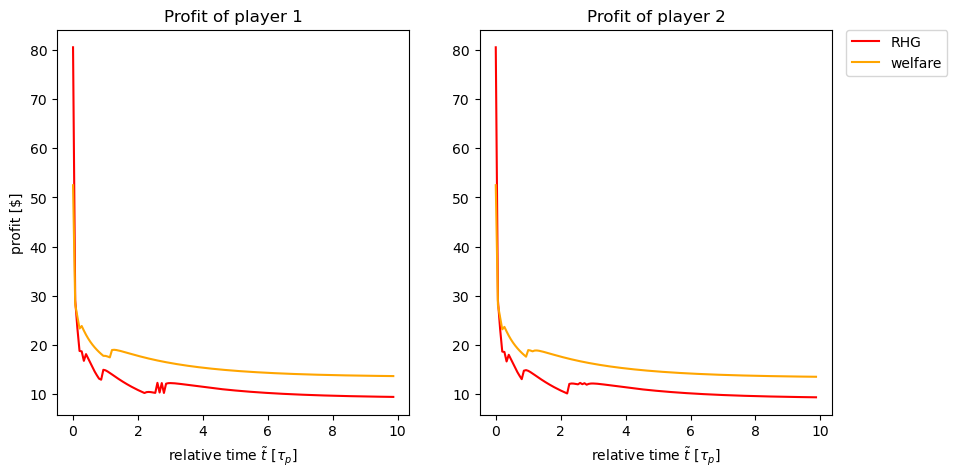

In [622]:
fig = plt.figure(figsize=(10,5))
ax = None
rel_times = np.arange(len(cost_data['total']['RHG'][distances[0]][1][0,:]))/param_data['dimensions']['tau_p']

# Player 1
ax = fig.add_subplot(1, 2, 1, sharey=ax)
ttl = f"Profit of player 1"
ax.set_title(ttl)
ax.set_ylabel(r"profit [\$]")
ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
ax.plot(rel_times, cost_data['total']['RHG'][distances[0]][1][0,:]/param_data['dimensions']['reference_pumping'], "red", label='RHG')
ax.plot(rel_times, cost_data['total']['finite welfare'][distances[0]][30][0,:]/param_data['dimensions']['reference_pumping'], "orange", label='welfare')

# Player 2
ax = fig.add_subplot(1, 2, 2, sharey=ax)
ttl = f"Profit of player 2"
ax.set_title(ttl)
ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
ax.plot(rel_times, cost_data['total']['RHG'][distances[0]][1][1,:]/param_data['dimensions']['reference_pumping'], "red", label='RHG')
ax.plot(rel_times, cost_data['total']['finite welfare'][distances[0]][30][1,:]/param_data['dimensions']['reference_pumping'], "orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [623]:
# Game/welfare input divergence
RHG_infinite_cost_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        cost_distances = np.linalg.norm(
            cost_data['total']['infinite welfare'][distance] - cost_data['total']['RHG'][distance][horizon],
            axis=0)
        cost_divergences = cost_distances / np.linalg.norm(
            cost_data['total']['infinite welfare'][distance], axis=0)
        RHG_infinite_cost_divergence[d][h] = cost_divergences.sum()/cost_divergences.shape[0]

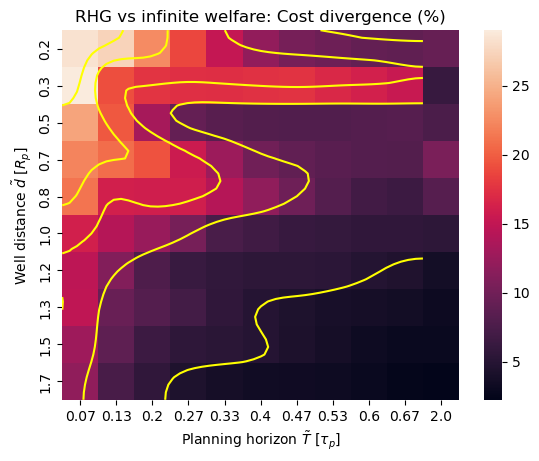

In [624]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_cost_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_cost_divergence[:,:-1].shape[1], RHG_infinite_cost_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_cost_divergence[:,:-1].shape[0], RHG_infinite_cost_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_cost_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs infinite welfare: Cost divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

#### Why this shape ? And why so different compared to input divergence ?

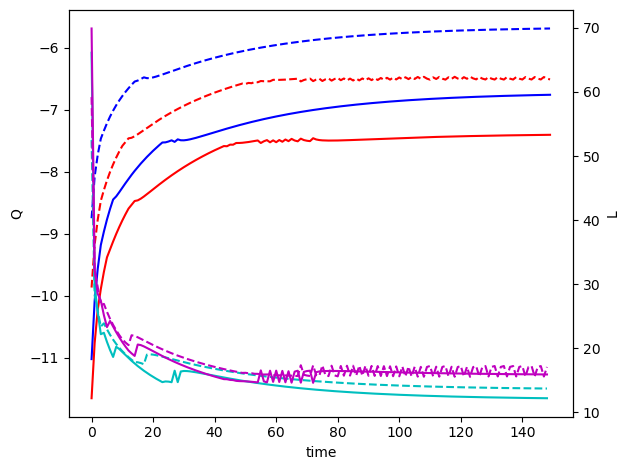

In [625]:
fig, ax1 = plt.subplots()

ax1.set_xlabel('time')
ax1.set_ylabel('Q')
ax1.plot(data['infinite welfare'][distances[0]][0,:], "b--")
ax1.plot(data['RHG'][distances[0]][horizon][0,:], "b")
ax1.plot(data['infinite welfare'][distances[1]][0,:], "r--")
ax1.plot(data['RHG'][distances[1]][horizon][0,:], "r")

ax2 = ax1.twinx()  # instantiate a second Axes that shares the same x-axis

ax2.set_ylabel('L')  # we already handled the x-label with ax1
ax2.plot(cost_data['total']['infinite welfare'][distances[0]][0,:], "c--")
ax2.plot(cost_data['total']['RHG'][distances[0]][horizon][0,:], "c")
ax2.plot(cost_data['total']['infinite welfare'][distances[1]][0,:], "m--")
ax2.plot(cost_data['total']['RHG'][distances[1]][horizon][0,:], "m")

fig.tight_layout()  # otherwise the right y-label is slightly clipped
plt.show()

In [626]:
head_data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_high_sell_avoid_borders/longer_Rp/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in head_data['finite welfare'].keys():
        head_data['finite welfare'][rel_distance] = {}
    head_data['finite welfare'][rel_distance][horizon] = result_data['h_wells']

# Infinite Horizon Welfare
for rel_distance in head_data['finite welfare'].keys():
    head_data['infinite welfare'][rel_distance] = head_data['finite welfare'][rel_distance][30]
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_high_sell_avoid_borders/longer_Rp/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in head_data['RHG'].keys():
        head_data['RHG'][rel_distance] = {}
    head_data['RHG'][rel_distance][horizon] = result_data['h_wells']

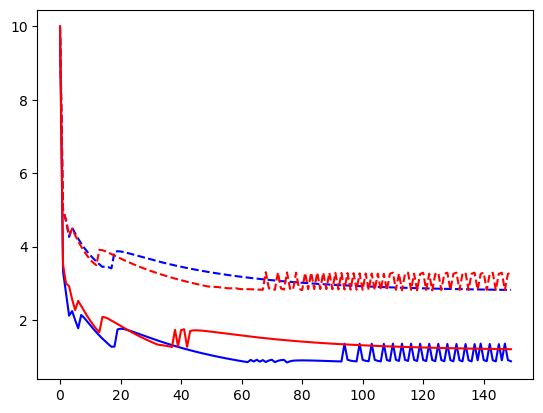

In [627]:
plt.plot(head_data['infinite welfare'][distances[0]][0,:], "b--")
plt.plot(head_data['RHG'][distances[0]][horizon][0,:], "b")
plt.plot(head_data['infinite welfare'][distances[1]][0,:], "r--")
plt.plot(head_data['RHG'][distances[1]][horizon][0,:], "r")

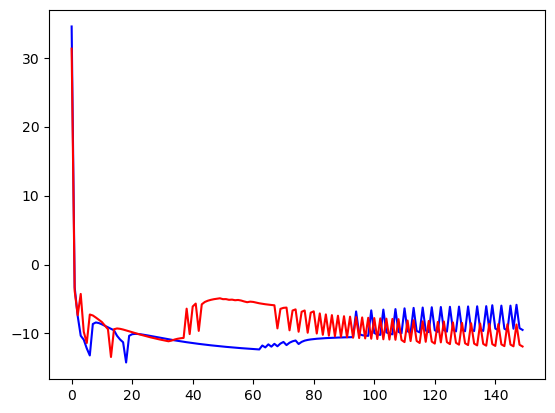

In [628]:

plt.plot(-head_data['RHG'][distances[0]][horizon][0,:]*data['RHG'][distances[0]][horizon][0,:] + head_data['infinite welfare'][distances[0]][0,:]*data['infinite welfare'][distances[0]][0,:], "b")
plt.plot(-head_data['RHG'][distances[1]][horizon][0,:]*data['RHG'][distances[1]][horizon][0,:] + head_data['infinite welfare'][distances[1]][0,:]*data['infinite welfare'][distances[1]][0,:], "r")

In [629]:
(-head_data['RHG'][distances[0]][horizon][0,:]*data['RHG'][distances[0]][horizon][0,:] + head_data['infinite welfare'][distances[0]][0,:]*data['infinite welfare'][distances[0]][0,:])[-1],\
(head_data['RHG'][distances[0]][horizon][0,:])[-1], (data['RHG'][distances[0]][horizon][0,:])[-1], \
(head_data['infinite welfare'][distances[0]][0,:])[-1] , (data['infinite welfare'][distances[0]][0,:])[-1]

(np.float64(-9.48689083659481),
 np.float64(0.8757978081703186),
 np.float64(-7.488731251163227),
 np.float64(2.819997549057007),
 np.float64(-5.689900424809117))

In [630]:
(-head_data['RHG'][distances[0]][horizon][0,:]*data['RHG'][distances[0]][horizon][0,:] + head_data['infinite welfare'][distances[0]][0,:]*data['infinite welfare'][distances[0]][0,:])[-1]
(-head_data['RHG'][distances[1]][horizon][0,:]*data['RHG'][distances[1]][horizon][0,:] + head_data['infinite welfare'][distances[1]][0,:]*data['infinite welfare'][distances[1]][0,:])[-1]

np.float64(-11.890858165473603)

In [631]:
param_data['costs']['extraction_cost'][0], alpha

(0.5, 6.0)

In [632]:
-0.5*(10*1.8+9.49) + 6*1.8, -0.5*(10*1.4+11.9) + 6*1.4, \
    -0.5*(10*1.8) + 6*1.8, -0.5*(10*1.4) + 6*1.4, -0.5*9.49, -0.5*11.9

(-2.9450000000000003,
 -4.550000000000001,
 1.8000000000000007,
 1.3999999999999986,
 -4.745,
 -5.95)

In [633]:
(cost_data['total']['infinite welfare'][distances[0]][0,:]- cost_data['total']['RHG'][distances[0]][horizon][0,:])[-1], \
(cost_data['total']['infinite welfare'][distances[1]][0,:] - cost_data['total']['RHG'][distances[1]][horizon][0,:])[-1]

(np.float64(2.8008866407506225), np.float64(4.40876885481908))

In [634]:
(data['infinite welfare'][distances[0]][0,:]- data['RHG'][distances[0]][horizon][0,:])[-1], \
(data['infinite welfare'][distances[1]][0,:] - data['RHG'][distances[1]][horizon][0,:])[-1]

(np.float64(1.7988308263541093), np.float64(1.3963915494129768))

CCL: pumping difference is less so profit difference is less, but -(pumping cost) difference is more and as it still has a important weighting, total profit is more.

In [635]:
2.9/cost_data['total']['infinite welfare'][distances[0]][0,:][-1], 4.4/cost_data['total']['infinite welfare'][distances[1]][0,:][-1]

(np.float64(0.2114108468495783), np.float64(0.2575439236414442))

In [636]:
head_data['infinite welfare'][distances[0]][0,-1], \
head_data['RHG'][distances[0]][horizon][0,-1], \
head_data['infinite welfare'][distances[1]][0,-1],\
head_data['RHG'][distances[1]][horizon][0,-1] 

(np.float64(2.819997549057007),
 np.float64(0.8757978081703186),
 np.float64(3.2887370586395264),
 np.float64(1.2043155431747437))

In [637]:
data['infinite welfare'][distances[0]][0,-1], \
data['RHG'][distances[0]][horizon][0,-1], \
data['infinite welfare'][distances[1]][0,-1],\
data['RHG'][distances[1]][horizon][0,-1]

(np.float64(-5.689900424809117),
 np.float64(-7.488731251163227),
 np.float64(-6.511424926336512),
 np.float64(-7.907816475749489))

In [638]:
0.5*(10-2.8)*5.6, 0.5*(10-3.3)*6.5, \
0.5*(10-0.9)*7.5, 0.5*(10-1.2)*7.9

(20.16, 21.775000000000002, 34.125, 34.760000000000005)

In [639]:
6*5.6, 6*6.5, 6*7.5, 6*7.9

(33.599999999999994, 39.0, 45.0, 47.400000000000006)

###

In [640]:
# Game/welfare cost divergence
RHG_aggregated_welfare_div = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        aggregated_welfare = (cost_data['total']['RHG'][distance][horizon].sum() - cost_data['total']['infinite welfare'][distance].sum()) / cost_data['total']['infinite welfare'][distance].sum()
        RHG_aggregated_welfare_div[d][h] = aggregated_welfare

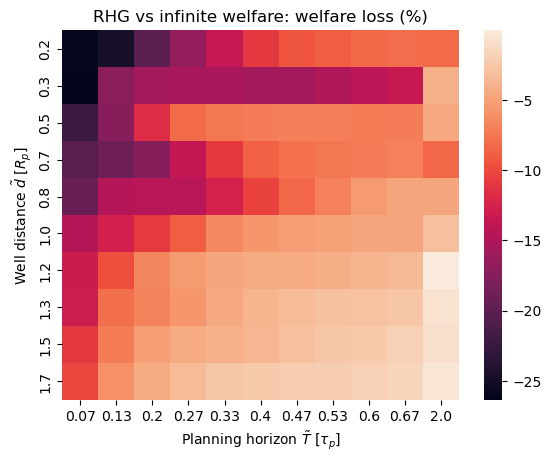

In [641]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_aggregated_welfare_div[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_aggregated_welfare_div[:,:-1].shape[1], RHG_aggregated_welfare_div[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_aggregated_welfare_div[:,:-1].shape[0], RHG_aggregated_welfare_div[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_aggregated_welfare_div*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs infinite welfare: welfare loss (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

In [642]:
# Game/welfare cost divergence
RHG_aggregated_welfare = np.zeros((len(distances), len(horizons)))
welfare_aggregated_welfare = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        RHG_aggregated_welfare[d][h] = cost_data['total']['RHG'][distance][horizon].sum()
        welfare_aggregated_welfare[d][h] = cost_data['total']['infinite welfare'][distance].sum()

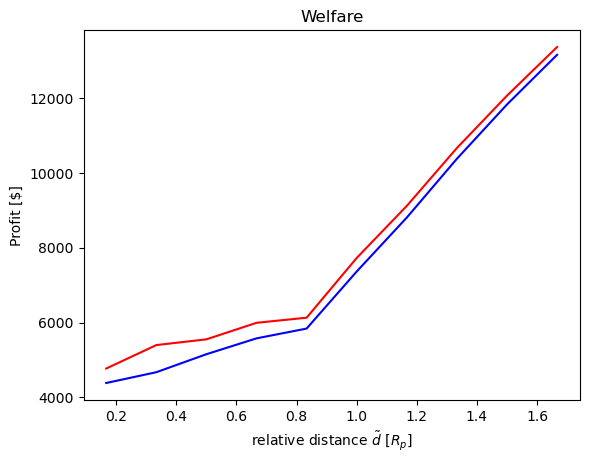

In [643]:
fig, ax = plt.subplots()
plt.plot(distances, RHG_aggregated_welfare[:,-2], "b")
plt.plot(distances, welfare_aggregated_welfare[:,-2], "r")

ax.set_title("Welfare")
ax.set_ylabel("Profit [\$]")
ax.set_xlabel(r"relative distance $\tilde d$ [$R_p$]")

plt.show()

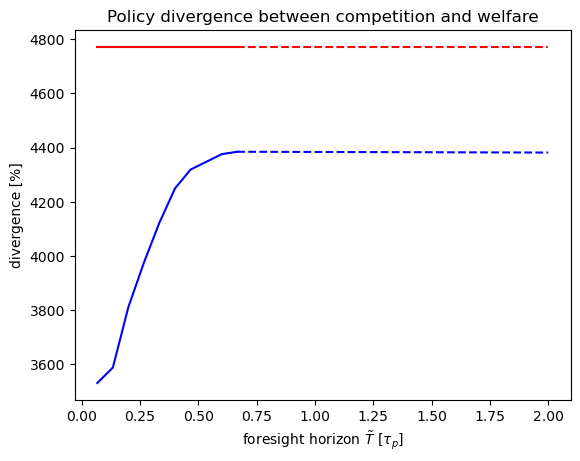

In [644]:
fig, ax = plt.subplots()
ax.plot(horizons[:-1]/param_data['dimensions']['tau_p'], RHG_aggregated_welfare[0,:-1], "b")
ax.plot(horizons[-2:]/param_data['dimensions']['tau_p'], RHG_aggregated_welfare[0,-2:], "b--")
ax.plot(horizons[:-1]/param_data['dimensions']['tau_p'], welfare_aggregated_welfare[0,:-1], "r")
ax.plot(horizons[-2:]/param_data['dimensions']['tau_p'], welfare_aggregated_welfare[0,-2:], "r--")

ax.set_title("Policy divergence between competition and welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel(r"foresight horizon $\tilde T$ [$\tau_p$]")

plt.show()

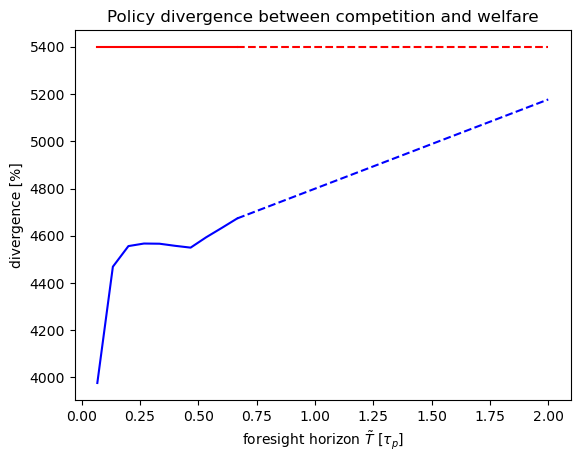

In [645]:
fig, ax = plt.subplots()
ax.plot(horizons[:-1]/param_data['dimensions']['tau_p'], RHG_aggregated_welfare[1,:-1], "b")
ax.plot(horizons[-2:]/param_data['dimensions']['tau_p'], RHG_aggregated_welfare[1,-2:], "b--")
ax.plot(horizons[:-1]/param_data['dimensions']['tau_p'], welfare_aggregated_welfare[1,:-1], "r")
ax.plot(horizons[-2:]/param_data['dimensions']['tau_p'], welfare_aggregated_welfare[1,-2:], "r--")

ax.set_title("Policy divergence between competition and welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel(r"foresight horizon $\tilde T$ [$\tau_p$]")

plt.show()

### Strange shape again: compare two costs (pumping and profit)

In [646]:
# Game/welfare cost divergence
RHG_aggregated_welfare_p = np.zeros((len(distances), len(horizons)))
welfare_aggregated_welfare_p = np.zeros((len(distances), len(horizons)))
RHG_aggregated_welfare_y = np.zeros((len(distances), len(horizons)))
welfare_aggregated_welfare_y = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        RHG_aggregated_welfare_p[d][h] = cost_data['pumping']['RHG'][distance][horizon].sum()
        welfare_aggregated_welfare_p[d][h] = cost_data['pumping']['infinite welfare'][distance].sum()
        RHG_aggregated_welfare_y[d][h] = cost_data['yield']['RHG'][distance][horizon].sum()
        welfare_aggregated_welfare_y[d][h] = cost_data['yield']['infinite welfare'][distance].sum()

Text(0.5, 0, 'foresight horizon $\\tilde T$ [$\\tau_p$]')

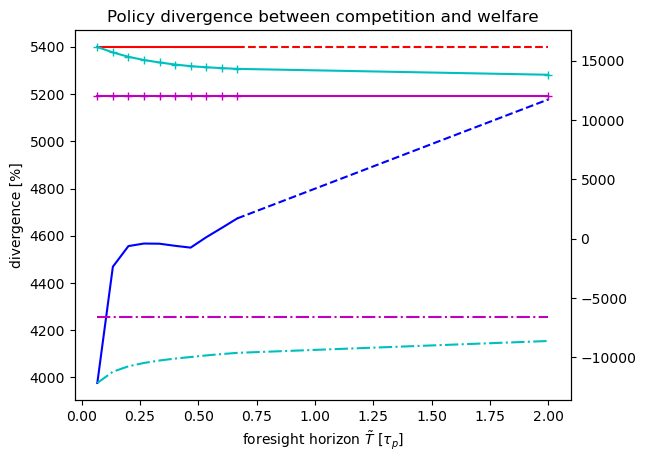

In [647]:
fig, ax = plt.subplots()
ax.plot(horizons[:-1]/param_data['dimensions']['tau_p'], RHG_aggregated_welfare[1,:-1], "b")
ax.plot(horizons[-2:]/param_data['dimensions']['tau_p'], RHG_aggregated_welfare[1,-2:], "b--")
ax.plot(horizons[:-1]/param_data['dimensions']['tau_p'], welfare_aggregated_welfare[1,:-1], "r")
ax.plot(horizons[-2:]/param_data['dimensions']['tau_p'], welfare_aggregated_welfare[1,-2:], "r--")

ax2 = ax.twinx()

ax2.plot(horizons[:]/param_data['dimensions']['tau_p'], RHG_aggregated_welfare_p[1,:], "c-.")
ax2.plot(horizons[:]/param_data['dimensions']['tau_p'], RHG_aggregated_welfare_y[1,:], "c-+")
ax2.plot(horizons[:]/param_data['dimensions']['tau_p'], welfare_aggregated_welfare_p[1,:], "m-.")
ax2.plot(horizons[:]/param_data['dimensions']['tau_p'], welfare_aggregated_welfare_y[1,:], "m-+")


ax.set_title("Policy divergence between competition and welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel(r"foresight horizon $\tilde T$ [$\tau_p$]")

In [648]:
k1=7
k2=8
cost_data['total']['RHG'][distances[1]][horizons[k1]].sum(), cost_data['pumping']['RHG'][distances[1]][horizons[k1]].sum(), cost_data['yield']['RHG'][distances[1]][horizons[k1]].sum(), \
cost_data['total']['RHG'][distances[1]][horizons[k2]].sum(), cost_data['pumping']['RHG'][distances[1]][horizons[k2]].sum(), cost_data['yield']['RHG'][distances[1]][horizons[k2]].sum()

(np.float64(4593.505734623229),
 np.float64(-9840.969281806269),
 np.float64(14434.475016429498),
 np.float64(4633.0127013269885),
 np.float64(-9726.941783243892),
 np.float64(14359.95448457088))

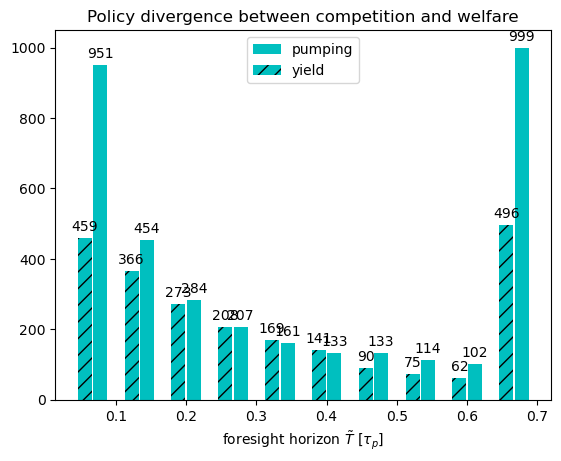

In [649]:
fig, ax = plt.subplots()
rects = ax.bar(horizons[:-1]/param_data['dimensions']['tau_p']+ 0.011, RHG_aggregated_welfare_p[1,1:]-RHG_aggregated_welfare_p[1,:-1], color="c", label='pumping', width=0.02)
ax.bar_label(rects, padding=3, fmt='%.0f')
rects = ax.bar(horizons[:-1]/param_data['dimensions']['tau_p'] - 0.011, -RHG_aggregated_welfare_y[1,1:]+RHG_aggregated_welfare_y[1,:-1], color="c", hatch="//", label='yield', width=0.02)
ax.bar_label(rects, padding=3, fmt='%.0f')

ax.set_title("Policy divergence between competition and welfare")
ax.set_xlabel(r"foresight horizon $\tilde T$ [$\tau_p$]")
plt.legend()

In [650]:
cost_data['total']['RHG'][distances[1]][horizons[-1]].sum(), cost_data['pumping']['RHG'][distances[1]][horizons[-1]].sum(), cost_data['yield']['RHG'][distances[1]][horizons[-1]].sum(), \
cost_data['total']['RHG'][distances[1]][horizons[-2]].sum(), cost_data['pumping']['RHG'][distances[1]][horizons[-2]].sum(), cost_data['yield']['RHG'][distances[1]][horizons[-2]].sum()

(np.float64(5177.108444011115),
 np.float64(-8625.22334403244),
 np.float64(13802.331788043557),
 np.float64(4673.435715901393),
 np.float64(-9624.532520426408),
 np.float64(14297.968236327804))

###

In [651]:
# Game/welfare water pumped
RHG_water_pumped = np.zeros((len(distances), len(horizons)))
welfare_water_pumped = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        RHG_water_pumped[d][h] = data['RHG'][distance][horizon].sum()
        welfare_water_pumped[d][h] = data['infinite welfare'][distance].sum()

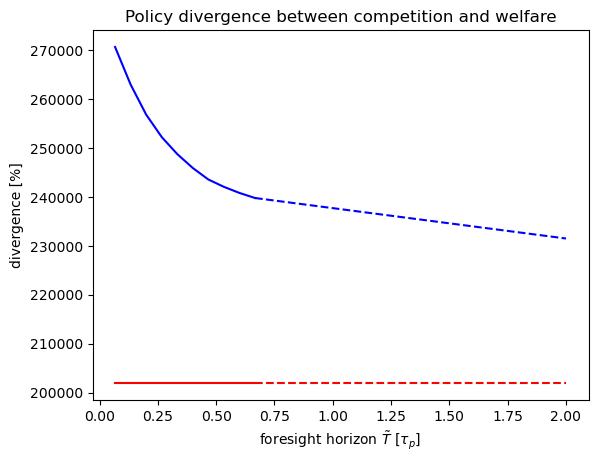

In [652]:
fig, ax = plt.subplots()
ax.plot(horizons[:-1]/param_data['dimensions']['tau_p'], -RHG_water_pumped[1,:-1]*100, "b")
ax.plot(horizons[-2:]/param_data['dimensions']['tau_p'], -RHG_water_pumped[1,-2:]*100, "b--")
ax.plot(horizons[:-1]/param_data['dimensions']['tau_p'], -welfare_water_pumped[1,:-1]*100, "r")
ax.plot(horizons[-2:]/param_data['dimensions']['tau_p'], -welfare_water_pumped[1,-2:]*100, "r--")

ax.set_title("Policy divergence between competition and welfare")
ax.set_ylabel("divergence [%]")
ax.set_xlabel(r"foresight horizon $\tilde T$ [$\tau_p$]")

plt.show()

Problem: why is welfare decreasing with horizon and why does the social planner generate less welfare ???

Fixed: the value given in "real_profit" is wrong: it doesn't multiply the profit by the time-varying yield coefficient.

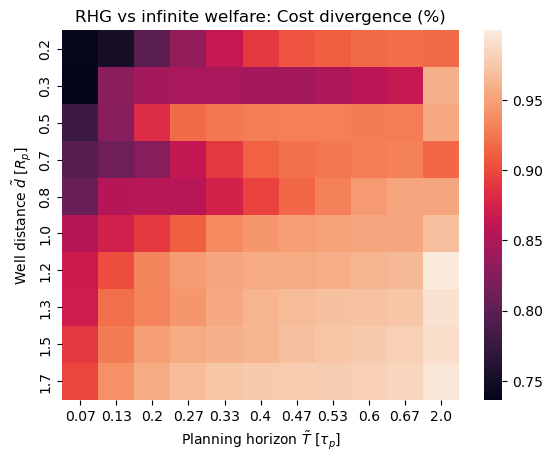

In [653]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom((RHG_aggregated_welfare[:,:-1].T/welfare_aggregated_welfare[:,-1]).T, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_aggregated_welfare[:,:-1].shape[1], RHG_aggregated_welfare[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_aggregated_welfare[:,:-1].shape[0], RHG_aggregated_welfare[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap((RHG_aggregated_welfare.T/welfare_aggregated_welfare[:,-1]).T,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs infinite welfare: Cost divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

# Dimensionless system -- Longer simulation + Cost inversion + Larger aquifer

## Build Data

In [254]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [255]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_larger/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data['finite welfare'].keys():
        data['finite welfare'][rel_distance] = {}
    data['finite welfare'][rel_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for rel_distance in data['finite welfare'].keys():
    data['infinite welfare'][rel_distance] = data['finite welfare'][rel_distance][30]

In [256]:
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_larger/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data['RHG'].keys():
        data['RHG'][rel_distance] = {}
    data['RHG'][rel_distance][horizon] = result_data['inputs']

## Display data

In [257]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [22]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

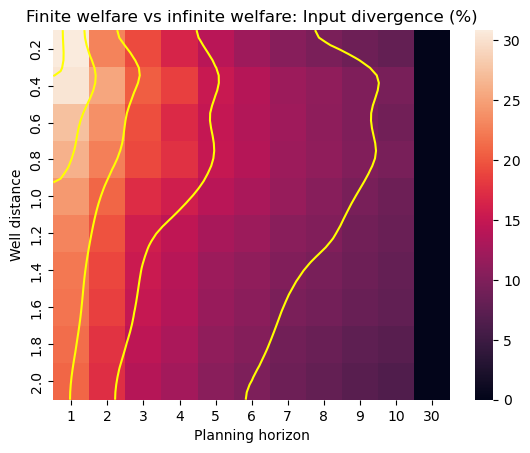

In [23]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, finite_infinite_divergence[:,:-1].shape[1], finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, finite_infinite_divergence[:,:-1].shape[0], finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [24]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(30.839874237432863), np.float64(30.272819737857894))

In [25]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

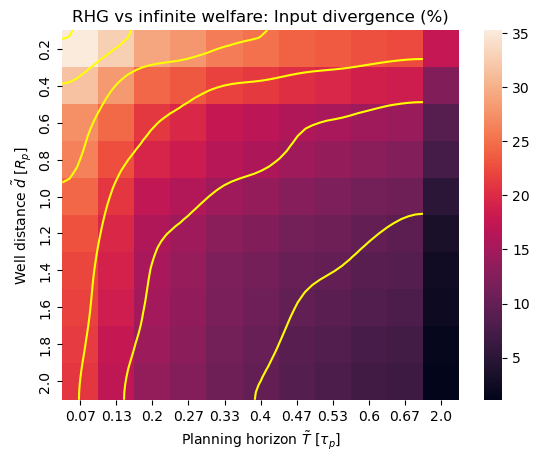

In [26]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_divergence[:,:-1].shape[1], RHG_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_divergence[:,:-1].shape[0], RHG_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

In [27]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(35.260519103281176), np.float64(1.110926239985304))

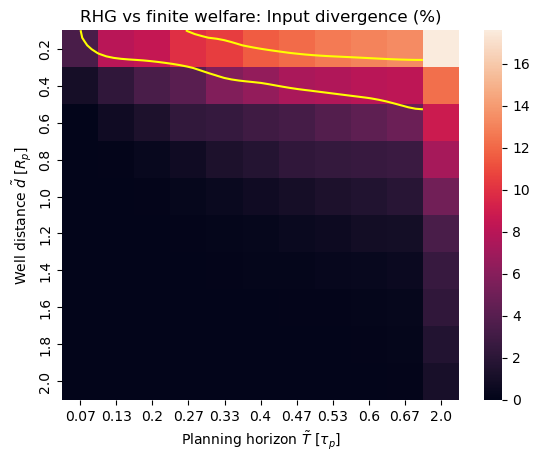

In [28]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_divergence[:,:-1].shape[1], RHG_finite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_divergence[:,:-1].shape[0], RHG_finite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

In [29]:
# RHG input divergence
RHG_finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['RHG'][distance][30] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['RHG'][distance][30], axis=0)
        RHG_finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

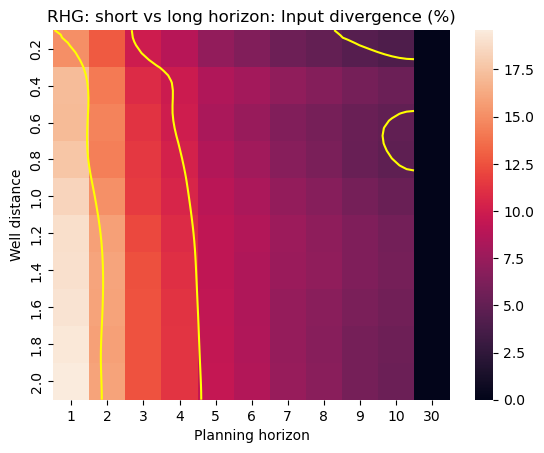

In [30]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[1], RHG_finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[0], RHG_finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("RHG: short vs long horizon: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [31]:
cost_data = {'total': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}, \
             'pumping': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}, \
                'yield': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}}
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_larger/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in cost_data['total']['finite welfare'].keys():
        cost_data['total']['finite welfare'][rel_distance] = {}
        cost_data['pumping']['finite welfare'][rel_distance] = {}
        cost_data['yield']['finite welfare'][rel_distance] = {}
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    # cost_heads = (result_data['h_wells'][:,1:] + result_data['h_wells'][:,:-1])/2
    cost_heads = result_data['h_wells'][:,1:] 
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = - alpha * result_data['q_rates'][:,:-1]
    cost_data['total']['finite welfare'][rel_distance][horizon] = pumping_cost + yield_profit
    cost_data['pumping']['finite welfare'][rel_distance][horizon] = pumping_cost
    cost_data['yield']['finite welfare'][rel_distance][horizon] = yield_profit

# Infinite Horizon Welfare
for rel_distance in cost_data['total']['finite welfare'].keys():
    cost_data['total']['infinite welfare'][rel_distance] = cost_data['total']['finite welfare'][rel_distance][30]
    cost_data['pumping']['infinite welfare'][rel_distance] = cost_data['pumping']['finite welfare'][rel_distance][30]
    cost_data['yield']['infinite welfare'][rel_distance] = cost_data['yield']['finite welfare'][rel_distance][30]

# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_larger/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in cost_data['total']['RHG'].keys():
        cost_data['total']['RHG'][rel_distance] = {}
        cost_data['pumping']['RHG'][rel_distance] = {}
        cost_data['yield']['RHG'][rel_distance] = {}
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    # cost_heads = (result_data['h_wells'][:,1:] + result_data['h_wells'][:,:-1])/2
    cost_heads = result_data['h_wells'][:,1:]
    profit = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1] - alpha * result_data['q_rates'][:,:-1]
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = -alpha * result_data['q_rates'][:,:-1]
    cost_data['total']['RHG'][rel_distance][horizon] = profit
    cost_data['pumping']['RHG'][rel_distance][horizon] = pumping_cost
    cost_data['yield']['RHG'][rel_distance][horizon] = yield_profit

In [32]:
# Game/welfare input divergence
RHG_infinite_cost_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        cost_distances = np.linalg.norm(
            cost_data['total']['infinite welfare'][distance] - cost_data['total']['RHG'][distance][horizon],
            axis=0)
        cost_divergences = cost_distances / np.linalg.norm(
            cost_data['total']['infinite welfare'][distance], axis=0)
        RHG_infinite_cost_divergence[d][h] = cost_divergences.sum()/cost_divergences.shape[0]

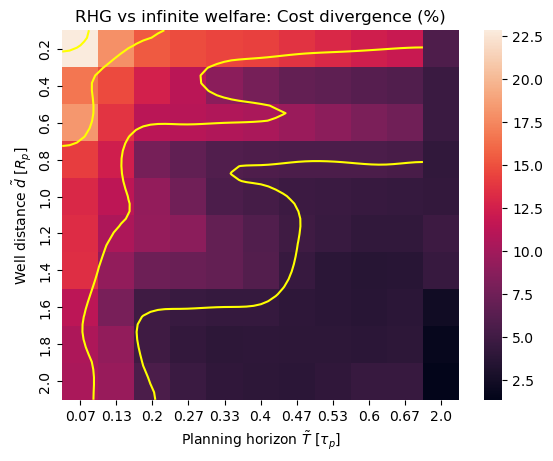

In [33]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_cost_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_cost_divergence[:,:-1].shape[1], RHG_infinite_cost_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_cost_divergence[:,:-1].shape[0], RHG_infinite_cost_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_cost_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs infinite welfare: Cost divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

### Article figures V2

As expected, myopic self-interested players pump more than centralized social-planner. The excess of water pumped (due to competition and lack of anticipation) is called common-pool overdraft.

In [739]:
# Game/welfare water pumped
RHG_water_pumped = np.zeros((len(distances), len(horizons)))
welfare_water_pumped = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        RHG_water_pumped[d][h] = data['RHG'][distance][horizon].sum()
        welfare_water_pumped[d][h] = data['infinite welfare'][distance].sum()
# Game/welfare cost divergence
RHG_aggregated_welfare = np.zeros((len(distances), len(horizons)))
welfare_aggregated_welfare = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        RHG_aggregated_welfare[d][h] = cost_data['total']['RHG'][distance][horizon].sum()
        welfare_aggregated_welfare[d][h] = cost_data['total']['infinite welfare'][distance].sum()

[]

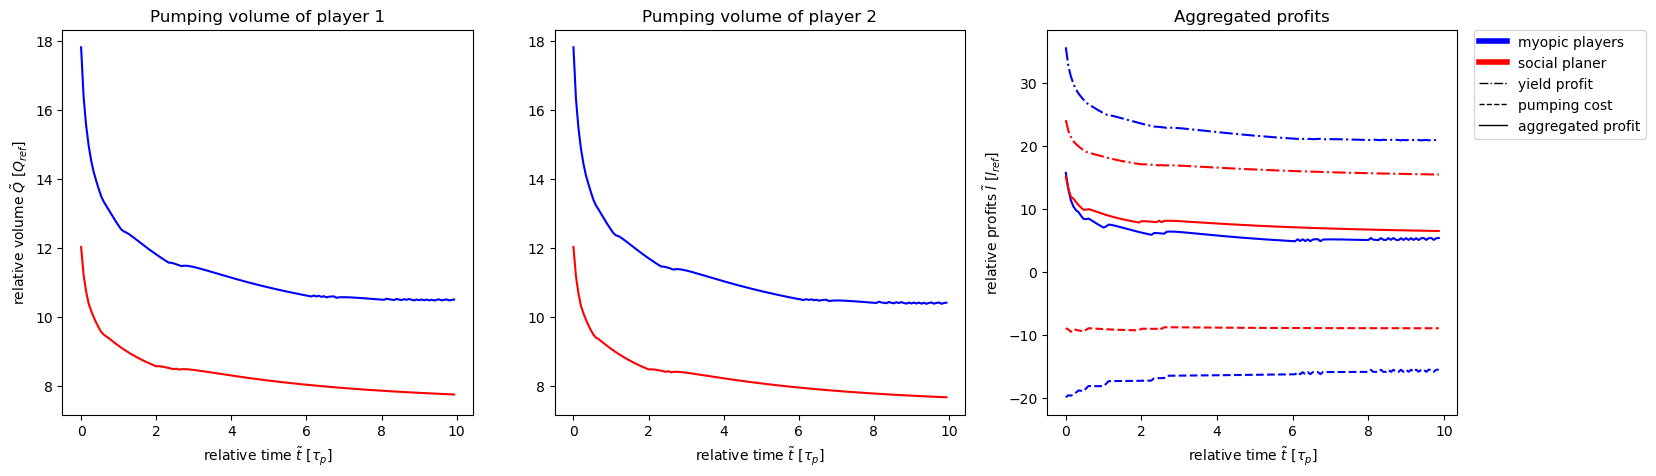

In [ ]:
fig = plt.figure(figsize=(18,5))
ax = None
rel_times = np.arange(len(data['RHG'][distances[0]][1][:4,:].sum(axis=0)))/param_data['dimensions']['tau_p']
RHG_color = "blue"
welfare_color = "red"

# Player 1
ax = fig.add_subplot(1, 3, 1, sharey=ax)
ttl = f"Pumping volume of player 1"
ax.set_title(ttl)
ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
ax.plot(rel_times, -data['RHG'][distances[0]][1][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], RHG_color, label='myopic players')
ax.plot(rel_times, -data['finite welfare'][distances[0]][30][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], welfare_color, label='social planer')

# Player 2
ax = fig.add_subplot(1, 3, 2, sharey=ax)
ttl = f"Pumping volume of player 2"
ax.set_title(ttl)
ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
ax.plot(rel_times, -data['RHG'][distances[0]][1][4:,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], RHG_color, label='myopic players')
ax.plot(rel_times, -data['finite welfare'][distances[0]][30][4:,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], welfare_color, label='social planer')
#ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Profits
ax = fig.add_subplot(1, 3, 3)
ttl = f"Aggregated profits"
ax.set_title(ttl)
ax.set_ylabel(r"relative profits $\tilde l$ [$l_{ref}$]")
ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
ax.plot(rel_times[:-1], cost_data['pumping']['RHG'][distances[0]][horizons[0]].sum(axis=0)/alpha, RHG_color, linestyle="--", label='myopic players')
ax.plot(rel_times[:-1], cost_data['pumping']['infinite welfare'][distances[0]].sum(axis=0)/alpha, welfare_color, linestyle="--", label='social planer')
ax.plot(rel_times[:-1], cost_data['yield']['RHG'][distances[0]][horizons[0]].sum(axis=0)/alpha, RHG_color, linestyle="-.", label='myopic players')
ax.plot(rel_times[:-1], cost_data['yield']['infinite welfare'][distances[0]].sum(axis=0)/alpha, welfare_color, linestyle="-.", label='social planer')
ax.plot(rel_times[:-1], cost_data['total']['RHG'][distances[0]][horizons[0]].sum(axis=0)/alpha, RHG_color, label='myopic players')
ax.plot(rel_times[:-1], cost_data['total']['infinite welfare'][distances[0]].sum(axis=0)/alpha, welfare_color, label='social planer')

# Custom legend
legend_elements = [mlines.Line2D([0], [0], color=RHG_color, lw=4, label='myopic players'),
                   mlines.Line2D([0], [0], color=welfare_color, lw=4, label='social planer'),
                   mlines.Line2D([0], [0], color='black', linestyle="-.", lw=1, label='yield profit'),
                   mlines.Line2D([0], [0], color='black', linestyle="--", lw=1, label='pumping cost'),
                   mlines.Line2D([0], [0], color='black', linestyle="-", lw=1, label='aggregated profit')]
ax.legend(handles=legend_elements, bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# ax = fig.add_subplot(2, 2, 3)
# ttl = f"Common-pool overdraft"
# ax.set_title(ttl)
# ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
# ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
# overdraft = (-data['RHG'][distances[0]][1][:,:].sum(axis=0) \
#         + data['finite welfare'][distances[0]][30][:,:].sum(axis=0))\
#                  /param_data['dimensions']['reference_pumping']
# ax.plot(rel_times, (overdraft), "blue")

# plt.savefig('../../Paper/figures/Fig1.svg', format='svg')
plt.plot()

When progressively increasing the horizon, overdraft reduce and welfare increases and get closer to social optimum (baseline)

In [741]:
# Additional overdraft for longer horizons
directory = 'run_data/two_wells_analysis_dimless_longer_larger/additional_data/finite_welfare'
welfare_pumping = []
welfare_cost = []
welfare_horizons = []
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    welfare_pumping.append(result_data['inputs'].sum())
    welfare_horizons.append(horizon)
    # Cost
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    cost_heads = result_data['h_wells'][:,:-1] 
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = - alpha * result_data['q_rates'][:,:-1]
    welfare_cost.append((pumping_cost + yield_profit).sum())
    

welfare_horizons_argsort = np.argsort(welfare_horizons)
welfare_pumping = np.array(welfare_pumping)[welfare_horizons_argsort]
welfare_cost = np.array(welfare_cost)[welfare_horizons_argsort]

directory = 'run_data/two_wells_analysis_dimless_longer_larger/additional_data/RHG'
RHG_pumping = []
RHG_cost = []
RHG_horizons = []
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    RHG_pumping.append(result_data['inputs'].sum())
    RHG_horizons.append(horizon)
    # Cost
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    cost_heads = result_data['h_wells'][:,:-1] 
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = - alpha * result_data['q_rates'][:,:-1]
    RHG_cost.append((pumping_cost + yield_profit).sum())

RHG_horizons_argsort = np.argsort(RHG_horizons)
RHG_pumping = np.array(RHG_pumping)[RHG_horizons_argsort]
RHG_cost = np.array(RHG_cost)[RHG_horizons_argsort]
RHG_horizons = np.array(RHG_horizons)[RHG_horizons_argsort]

horizons_extended = np.hstack((np.sort(list(data['finite welfare'][distances[0]].keys())),RHG_horizons))
arg_horizons = np.argsort(horizons_extended)
horizons_extended = np.array(horizons_extended)[arg_horizons]

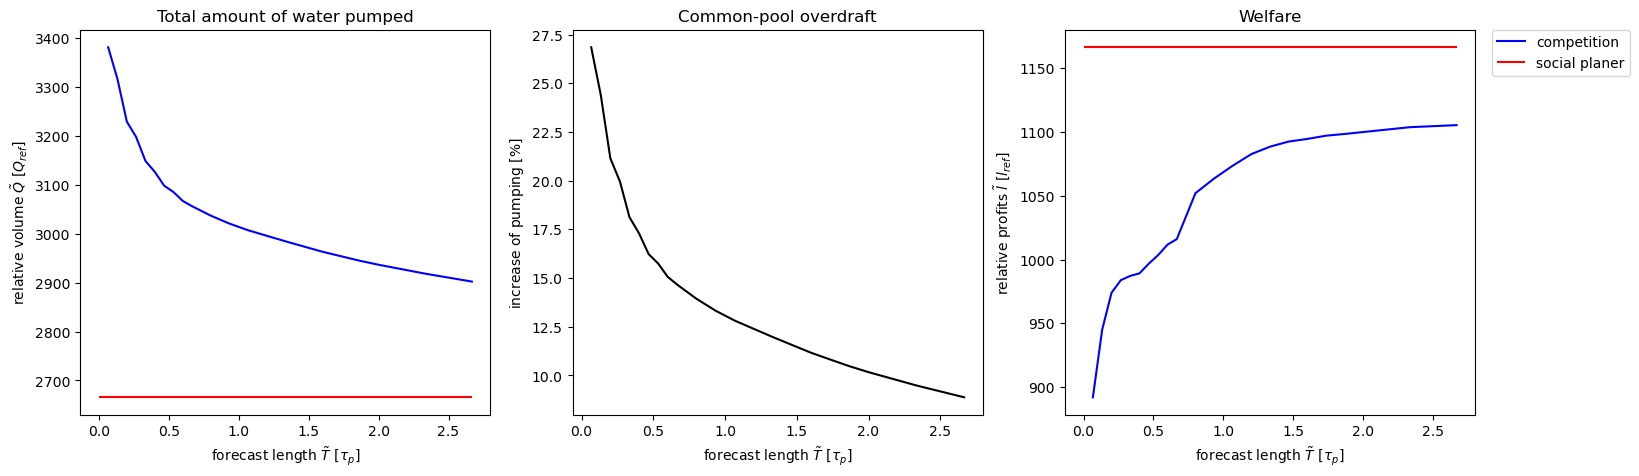

In [742]:
fig = plt.figure(figsize=(18,5))

# Water pumped
ax = fig.add_subplot(1, 3, 1)
ax.plot(horizons_extended/param_data['dimensions']['tau_p'], -np.hstack((RHG_water_pumped[0,:], RHG_pumping))[arg_horizons], "b")
ax.hlines(max(-np.hstack((welfare_water_pumped[0,:], welfare_pumping))[arg_horizons]), 0, horizons_extended[-1]/param_data['dimensions']['tau_p'], "r")

ax.set_title("Total amount of water pumped")
ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_xlabel(r"forecast length $\tilde T$ [$\tau_p$]")

# Overdraft
ax = fig.add_subplot(1, 3, 2)
# ax.plot(horizons_extended/param_data['dimensions']['tau_p'], -np.hstack((RHG_water_pumped[0,:], RHG_pumping))[arg_horizons] + min(np.hstack((welfare_water_pumped[0,:], welfare_pumping))), "black")
ax.plot(horizons_extended/param_data['dimensions']['tau_p'],\
    100*(np.hstack((RHG_water_pumped[0,:], RHG_pumping))[arg_horizons] - \
        min(np.hstack((welfare_water_pumped[0,:], welfare_pumping))))/ \
            min(np.hstack((welfare_water_pumped[0,:], welfare_pumping))), "black")

ax.set_title("Common-pool overdraft")
# ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_ylabel(r"increase of pumping [$\%$]")
ax.set_xlabel(r"forecast length $\tilde T$ [$\tau_p$]")

# Welfare
ax2 = fig.add_subplot(1, 3, 3)
ax2.plot(np.delete(horizons_extended,-3)/param_data['dimensions']['tau_p'], \
    np.delete(np.hstack((RHG_aggregated_welfare[0,:], RHG_cost))[arg_horizons], (-3))/alpha, \
        "b", label='competition')
ax2.hlines(max(np.hstack((welfare_aggregated_welfare[0,:], welfare_cost))[arg_horizons]/alpha),
           0, max(horizons_extended/param_data['dimensions']['tau_p']), "r"\
               , label='social planer')

ax2.set_title("Welfare")
ax2.set_ylabel(r"relative profits $\tilde l$ [$l_{ref}$]")
ax2.set_xlabel(r"forecast length $\tilde T$ [$\tau_p$]")

ax2.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# plt.savefig('../../Paper/figures/Fig2.svg', format='svg')
plt.show()

In [743]:
RHG_aggregated_welfare[0,:]/alpha, RHG_cost/alpha, arg_horizons, RHG_horizons

(array([ 892.18628454,  945.1978772 ,  974.01555637,  983.90494396,
         987.17883447,  989.21689524,  996.81744149, 1003.5251929 ,
        1011.65878178, 1016.02553316, 1081.75573891]),
 array([1051.95700726, 1063.43308507, 1073.47762217, 1082.56677537,
        1088.37021885, 1092.35666216, 1094.41662328, 1096.94287994,
        1098.30393345, 1103.60698408, 1105.21530753]),
 array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 10, 20, 21]),
 array([12, 14, 16, 18, 20, 22, 24, 26, 28, 35, 40]))

In [744]:
(RHG_cost[-1] - welfare_cost[-1])/welfare_cost[-1]

np.float64(-0.03375630900796799)

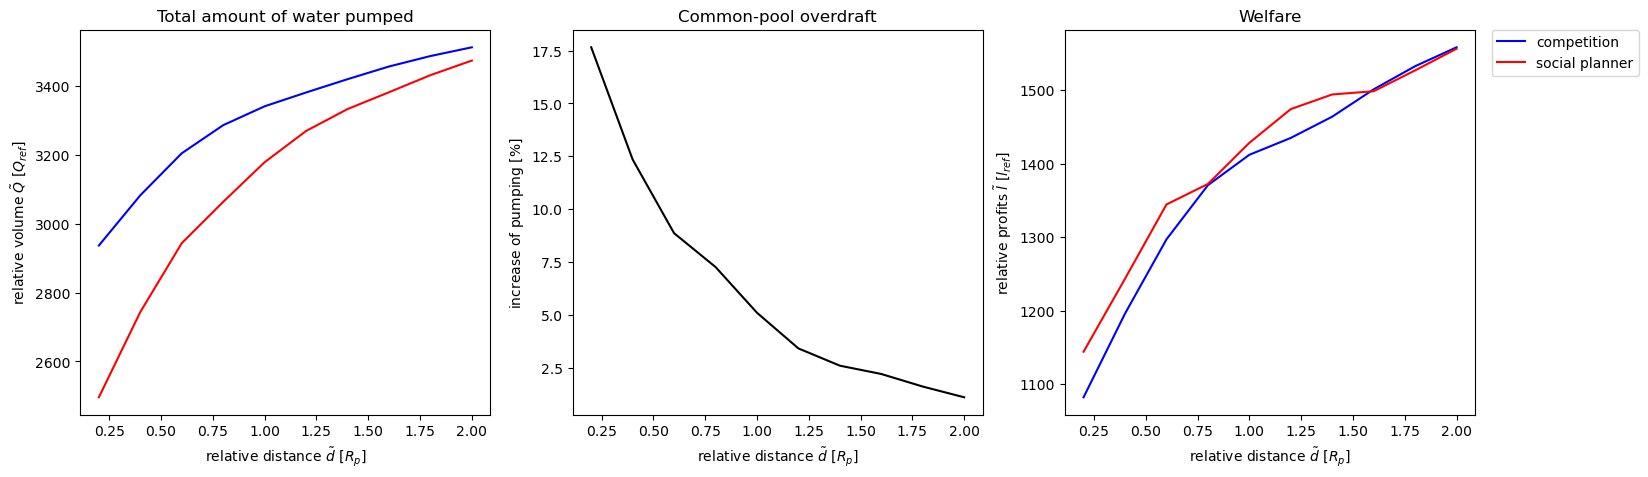

In [745]:
fig = plt.figure(figsize=(18,5))

# Water pumped
ax = fig.add_subplot(1, 3, 1)
ax.plot(distances, -RHG_water_pumped[:,-1], "b")
ax.plot(distances, -welfare_water_pumped[:,-1], "r")

ax.set_title("Total amount of water pumped")
ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_xlabel(r"relative distance $\tilde d$ [$R_p$]")

# Overdraft
ax = fig.add_subplot(1, 3, 2)
# ax.plot(distances, (RHG_water_pumped[:,-1] - welfare_water_pumped[:,-1]), "black")
ax.plot(distances, 100*(RHG_water_pumped[:,-1] - welfare_water_pumped[:,-1])/welfare_water_pumped[:,-1], "black")

ax.set_title("Common-pool overdraft")
# ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_ylabel(r"increase of pumping [$\%$]")
ax.set_xlabel(r"relative distance $\tilde d$ [$R_p$]")

# Welfare
ax2 = fig.add_subplot(1, 3, 3)
ax2.plot(distances, RHG_aggregated_welfare[:,-1]/alpha, "b", label = "competition")
ax2.plot(distances, welfare_aggregated_welfare[:,-1]/alpha, "r", label = "social planner")

ax2.set_title("Welfare")
ax2.set_ylabel(r"relative profits $\tilde l$ [$l_{ref}$]")
ax2.set_xlabel(r"relative distance $\tilde d$ [$R_p$]")

ax2.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# plt.savefig('../../Paper/figures/Fig3.svg', format='svg')
plt.show()

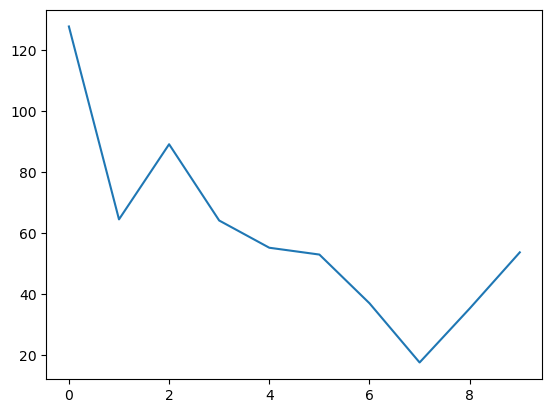

In [746]:
plt.plot(-(RHG_aggregated_welfare[:,-2]/alpha)+(welfare_aggregated_welfare[:,-2]/alpha))

Combining both dimensions allows us to evaluate the overdraft resulting from different forecast ability and spatial configuration.

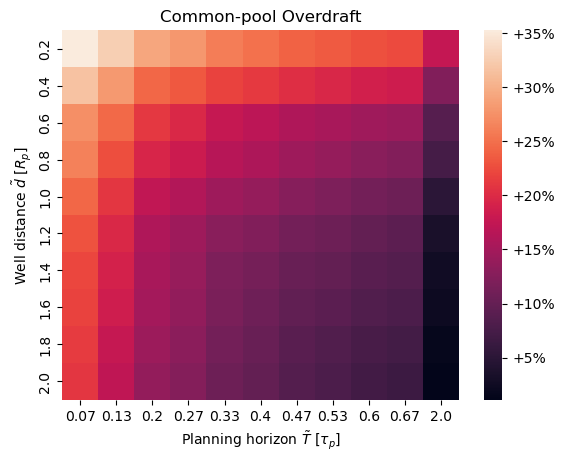

In [ ]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_divergence[:,:-1].shape[1], RHG_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_divergence[:,:-1].shape[0], RHG_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1),
                cbar_kws={'format': '+%.0f%%'})

plt.title("Common-pool Overdraft")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

# plt.savefig('../../Paper/figures/Fig4_alt.svg', format='svg')
plt.show()

# Dimensionless system -- Longer simulation + Cost inversion + Larger aquifer + Longer Rp

## Build Data

In [694]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [695]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_larger/longer_Rp/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data['finite welfare'].keys():
        data['finite welfare'][rel_distance] = {}
    data['finite welfare'][rel_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for rel_distance in data['finite welfare'].keys():
    data['infinite welfare'][rel_distance] = data['finite welfare'][rel_distance][30]

In [696]:
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_larger/longer_Rp/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data['RHG'].keys():
        data['RHG'][rel_distance] = {}
    data['RHG'][rel_distance][horizon] = result_data['inputs']

## Display data

In [697]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [698]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

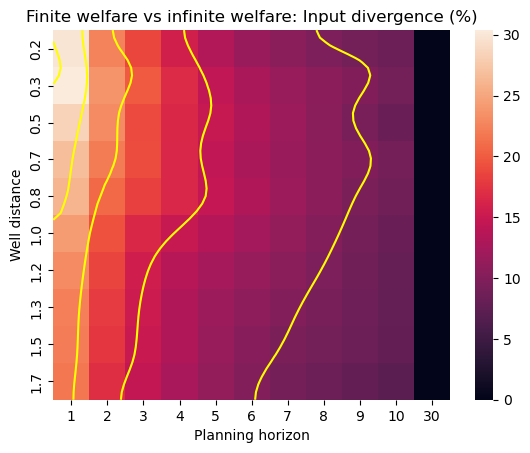

In [699]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, finite_infinite_divergence[:,:-1].shape[1], finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, finite_infinite_divergence[:,:-1].shape[0], finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [700]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(29.869956104170697), np.float64(30.375299079108885))

In [701]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

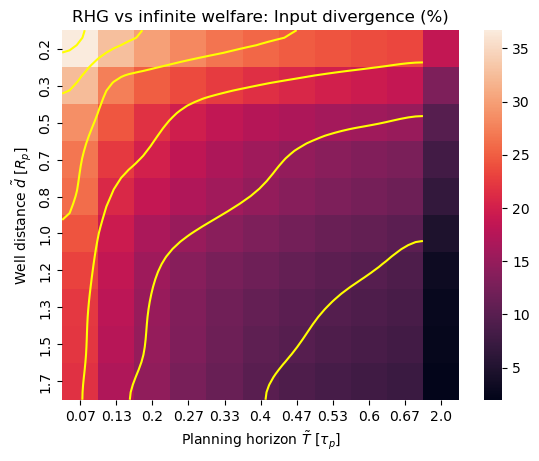

In [702]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_divergence[:,:-1].shape[1], RHG_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_divergence[:,:-1].shape[0], RHG_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

In [703]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(36.706885660480225), np.float64(1.9841006015905094))

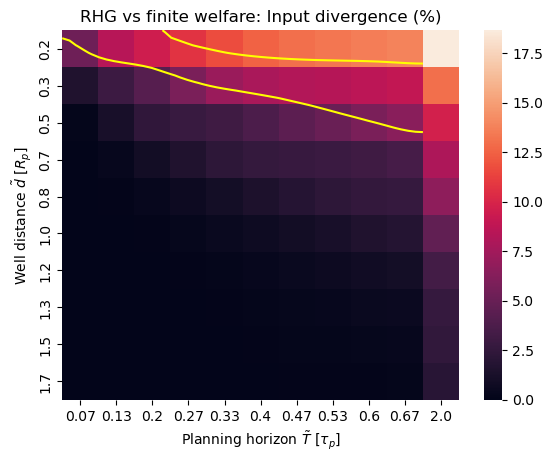

In [704]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_divergence[:,:-1].shape[1], RHG_finite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_divergence[:,:-1].shape[0], RHG_finite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

In [705]:
# RHG input divergence
RHG_finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['RHG'][distance][30] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['RHG'][distance][30], axis=0)
        RHG_finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

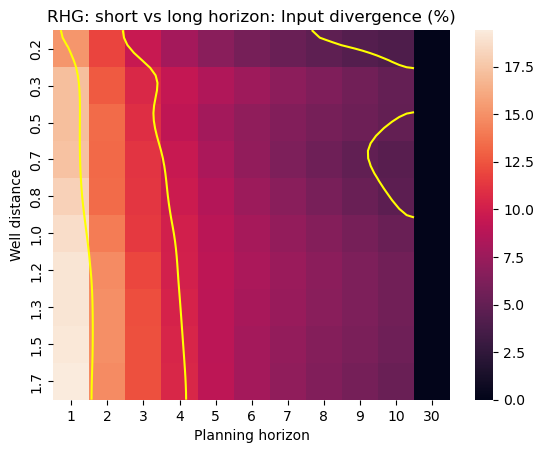

In [706]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[1], RHG_finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[0], RHG_finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("RHG: short vs long horizon: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [709]:
cost_data = {'total': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}, \
             'pumping': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}, \
                'yield': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}}
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_larger/longer_Rp/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in cost_data['total']['finite welfare'].keys():
        cost_data['total']['finite welfare'][rel_distance] = {}
        cost_data['pumping']['finite welfare'][rel_distance] = {}
        cost_data['yield']['finite welfare'][rel_distance] = {}
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    # cost_heads = (result_data['h_wells'][:,1:] + result_data['h_wells'][:,:-1])/2
    cost_heads = result_data['h_wells'][:,1:] 
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = - alpha * result_data['q_rates'][:,:-1]
    cost_data['total']['finite welfare'][rel_distance][horizon] = pumping_cost + yield_profit
    cost_data['pumping']['finite welfare'][rel_distance][horizon] = pumping_cost
    cost_data['yield']['finite welfare'][rel_distance][horizon] = yield_profit

# Infinite Horizon Welfare
for rel_distance in cost_data['total']['finite welfare'].keys():
    cost_data['total']['infinite welfare'][rel_distance] = cost_data['total']['finite welfare'][rel_distance][30]
    cost_data['pumping']['infinite welfare'][rel_distance] = cost_data['pumping']['finite welfare'][rel_distance][30]
    cost_data['yield']['infinite welfare'][rel_distance] = cost_data['yield']['finite welfare'][rel_distance][30]

# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_larger/longer_Rp/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in cost_data['total']['RHG'].keys():
        cost_data['total']['RHG'][rel_distance] = {}
        cost_data['pumping']['RHG'][rel_distance] = {}
        cost_data['yield']['RHG'][rel_distance] = {}
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    # cost_heads = (result_data['h_wells'][:,1:] + result_data['h_wells'][:,:-1])/2
    cost_heads = result_data['h_wells'][:,1:]
    profit = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1] - alpha * result_data['q_rates'][:,:-1]
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = -alpha * result_data['q_rates'][:,:-1]
    cost_data['total']['RHG'][rel_distance][horizon] = profit
    cost_data['pumping']['RHG'][rel_distance][horizon] = pumping_cost
    cost_data['yield']['RHG'][rel_distance][horizon] = yield_profit

In [710]:
# Game/welfare input divergence
RHG_infinite_cost_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        cost_distances = np.linalg.norm(
            cost_data['total']['infinite welfare'][distance] - cost_data['total']['RHG'][distance][horizon],
            axis=0)
        cost_divergences = cost_distances / np.linalg.norm(
            cost_data['total']['infinite welfare'][distance], axis=0)
        RHG_infinite_cost_divergence[d][h] = cost_divergences.sum()/cost_divergences.shape[0]

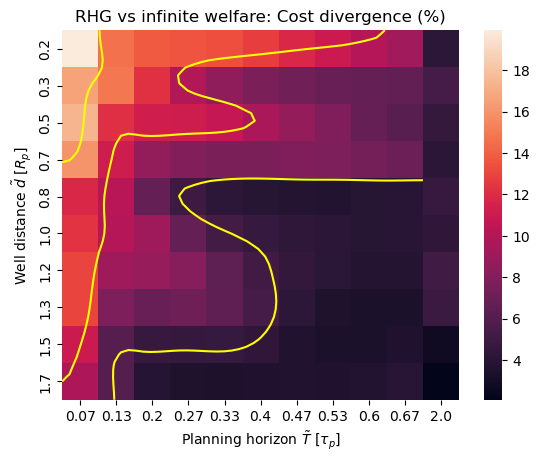

In [711]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_cost_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_cost_divergence[:,:-1].shape[1], RHG_infinite_cost_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_cost_divergence[:,:-1].shape[0], RHG_infinite_cost_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_cost_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs infinite welfare: Cost divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

### Article figures V2

As expected, myopic self-interested players pump more than centralized social-planner. The excess of water pumped (due to competition and lack of anticipation) is called common-pool overdraft.

In [712]:
# Game/welfare water pumped
RHG_water_pumped = np.zeros((len(distances), len(horizons)))
welfare_water_pumped = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        RHG_water_pumped[d][h] = data['RHG'][distance][horizon].sum()
        welfare_water_pumped[d][h] = data['infinite welfare'][distance].sum()
# Game/welfare cost divergence
RHG_aggregated_welfare = np.zeros((len(distances), len(horizons)))
welfare_aggregated_welfare = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        RHG_aggregated_welfare[d][h] = cost_data['total']['RHG'][distance][horizon].sum()
        welfare_aggregated_welfare[d][h] = cost_data['total']['infinite welfare'][distance].sum()

[]

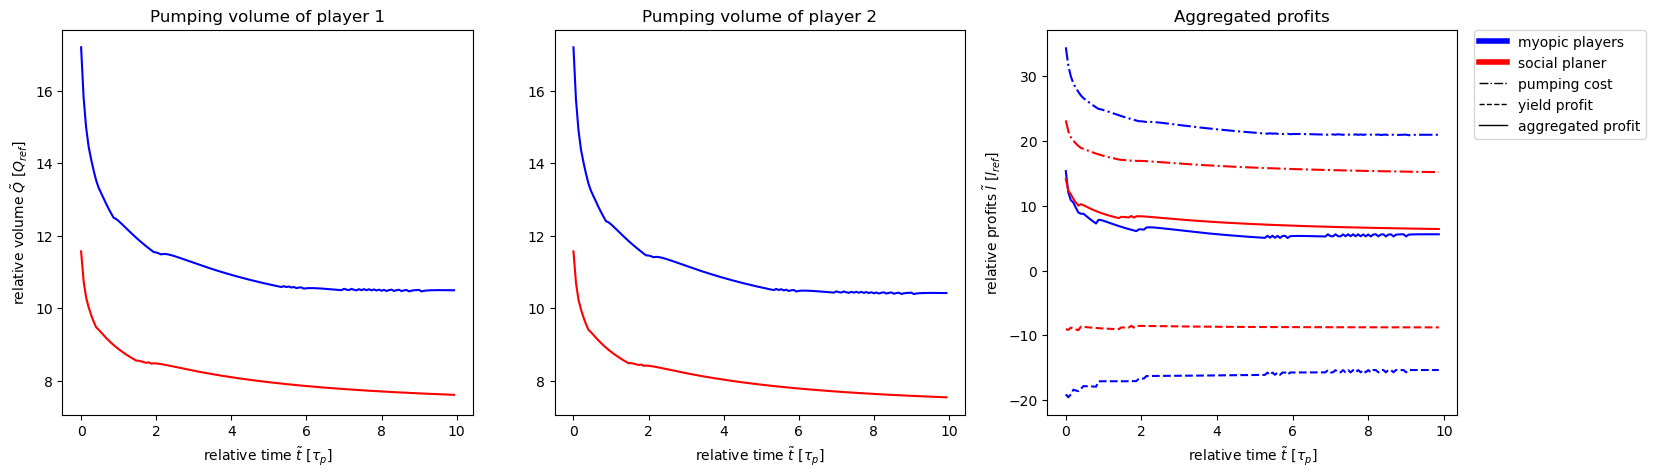

In [ ]:
fig = plt.figure(figsize=(18,5))
ax = None
rel_times = np.arange(len(data['RHG'][distances[0]][1][:4,:].sum(axis=0)))/param_data['dimensions']['tau_p']
RHG_color = "blue"
welfare_color = "red"

# Player 1
ax = fig.add_subplot(1, 3, 1, sharey=ax)
ttl = f"Pumping volume of player 1"
ax.set_title(ttl)
ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
ax.plot(rel_times, -data['RHG'][distances[0]][1][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], RHG_color, label='myopic players')
ax.plot(rel_times, -data['finite welfare'][distances[0]][30][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], welfare_color, label='social planer')

# Player 2
ax = fig.add_subplot(1, 3, 2, sharey=ax)
ttl = f"Pumping volume of player 2"
ax.set_title(ttl)
ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
ax.plot(rel_times, -data['RHG'][distances[0]][1][4:,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], RHG_color, label='myopic players')
ax.plot(rel_times, -data['finite welfare'][distances[0]][30][4:,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], welfare_color, label='social planer')
#ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Profits
ax = fig.add_subplot(1, 3, 3)
ttl = f"Aggregated profits"
ax.set_title(ttl)
ax.set_ylabel(r"relative profits $\tilde l$ [$l_{ref}$]")
ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
ax.plot(rel_times[:-1], cost_data['pumping']['RHG'][distances[0]][horizons[0]].sum(axis=0)/alpha, RHG_color, linestyle="--", label='myopic players')
ax.plot(rel_times[:-1], cost_data['pumping']['infinite welfare'][distances[0]].sum(axis=0)/alpha, welfare_color, linestyle="--", label='social planer')
ax.plot(rel_times[:-1], cost_data['yield']['RHG'][distances[0]][horizons[0]].sum(axis=0)/alpha, RHG_color, linestyle="-.", label='myopic players')
ax.plot(rel_times[:-1], cost_data['yield']['infinite welfare'][distances[0]].sum(axis=0)/alpha, welfare_color, linestyle="-.", label='social planer')
ax.plot(rel_times[:-1], cost_data['total']['RHG'][distances[0]][horizons[0]].sum(axis=0)/alpha, RHG_color, label='myopic players')
ax.plot(rel_times[:-1], cost_data['total']['infinite welfare'][distances[0]].sum(axis=0)/alpha, welfare_color, label='social planer')

# Custom legend
legend_elements = [mlines.Line2D([0], [0], color=RHG_color, lw=4, label='myopic players'),
                   mlines.Line2D([0], [0], color=welfare_color, lw=4, label='social planer'),
                   mlines.Line2D([0], [0], color='black', linestyle="-.", lw=1, label='pumping cost'),
                   mlines.Line2D([0], [0], color='black', linestyle="--", lw=1, label='yield profit'),
                   mlines.Line2D([0], [0], color='black', linestyle="-", lw=1, label='aggregated profit')]
ax.legend(handles=legend_elements, bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# ax = fig.add_subplot(2, 2, 3)
# ttl = f"Common-pool overdraft"
# ax.set_title(ttl)
# ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
# ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
# overdraft = (-data['RHG'][distances[0]][1][:,:].sum(axis=0) \
#         + data['finite welfare'][distances[0]][30][:,:].sum(axis=0))\
#                  /param_data['dimensions']['reference_pumping']
# ax.plot(rel_times, (overdraft), "blue")

# plt.savefig('../../Paper/figures/Fig1.svg', format='svg')
plt.plot()

When progressively increasing the horizon, overdraft reduce and welfare increases and get closer to social optimum (baseline)

In [714]:
# Additional overdraft for longer horizons
directory = 'run_data/two_wells_analysis_dimless_longer_larger/additional_data/finite_welfare'
welfare_pumping = []
welfare_cost = []
welfare_horizons = []
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    welfare_pumping.append(result_data['inputs'].sum())
    welfare_horizons.append(horizon)
    # Cost
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    cost_heads = result_data['h_wells'][:,:-1] 
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = - alpha * result_data['q_rates'][:,:-1]
    welfare_cost.append((pumping_cost + yield_profit).sum())
    

welfare_horizons_argsort = np.argsort(welfare_horizons)
welfare_pumping = np.array(welfare_pumping)[welfare_horizons_argsort]
welfare_cost = np.array(welfare_cost)[welfare_horizons_argsort]

directory = 'run_data/two_wells_analysis_dimless_longer_larger/additional_data/RHG'
RHG_pumping = []
RHG_cost = []
RHG_horizons = []
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    RHG_pumping.append(result_data['inputs'].sum())
    RHG_horizons.append(horizon)
    # Cost
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    cost_heads = result_data['h_wells'][:,:-1] 
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = - alpha * result_data['q_rates'][:,:-1]
    RHG_cost.append((pumping_cost + yield_profit).sum())

RHG_horizons_argsort = np.argsort(RHG_horizons)
RHG_pumping = np.array(RHG_pumping)[RHG_horizons_argsort]
RHG_cost = np.array(RHG_cost)[RHG_horizons_argsort]
RHG_horizons = np.array(RHG_horizons)[RHG_horizons_argsort]

horizons_extended = np.hstack((np.sort(list(data['finite welfare'][distances[0]].keys())),RHG_horizons))
arg_horizons = np.argsort(horizons_extended)
horizons_extended = np.array(horizons_extended)[arg_horizons]

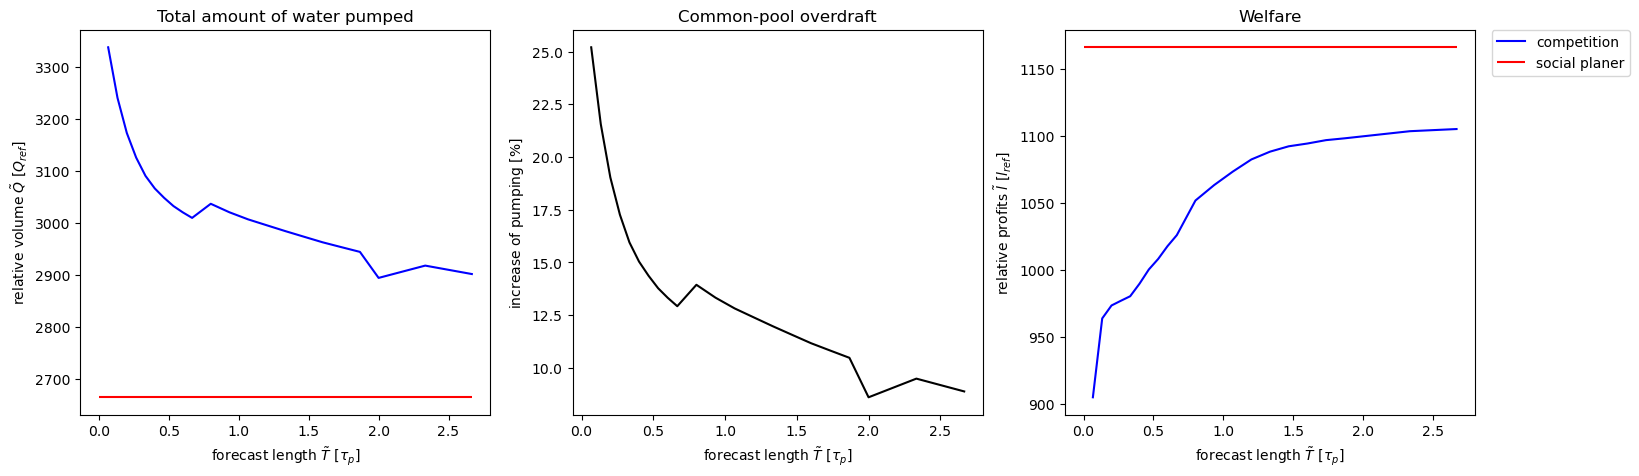

In [715]:
fig = plt.figure(figsize=(18,5))

# Water pumped
ax = fig.add_subplot(1, 3, 1)
ax.plot(horizons_extended/param_data['dimensions']['tau_p'], -np.hstack((RHG_water_pumped[0,:], RHG_pumping))[arg_horizons], "b")
ax.hlines(max(-np.hstack((welfare_water_pumped[0,:], welfare_pumping))[arg_horizons]), 0, horizons_extended[-1]/param_data['dimensions']['tau_p'], "r")

ax.set_title("Total amount of water pumped")
ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_xlabel(r"forecast length $\tilde T$ [$\tau_p$]")

# Overdraft
ax = fig.add_subplot(1, 3, 2)
# ax.plot(horizons_extended/param_data['dimensions']['tau_p'], -np.hstack((RHG_water_pumped[0,:], RHG_pumping))[arg_horizons] + min(np.hstack((welfare_water_pumped[0,:], welfare_pumping))), "black")
ax.plot(horizons_extended/param_data['dimensions']['tau_p'],\
    100*(np.hstack((RHG_water_pumped[0,:], RHG_pumping))[arg_horizons] - \
        min(np.hstack((welfare_water_pumped[0,:], welfare_pumping))))/ \
            min(np.hstack((welfare_water_pumped[0,:], welfare_pumping))), "black")

ax.set_title("Common-pool overdraft")
# ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_ylabel(r"increase of pumping [$\%$]")
ax.set_xlabel(r"forecast length $\tilde T$ [$\tau_p$]")

# Welfare
ax2 = fig.add_subplot(1, 3, 3)
ax2.plot(np.delete(horizons_extended,-3)/param_data['dimensions']['tau_p'], \
    np.delete(np.hstack((RHG_aggregated_welfare[0,:], RHG_cost))[arg_horizons], (-3))/alpha, \
        "b", label='competition')
ax2.hlines(max(np.hstack((welfare_aggregated_welfare[0,:], welfare_cost))[arg_horizons]/alpha),
           0, max(horizons_extended/param_data['dimensions']['tau_p']), "r"\
               , label='social planer')

ax2.set_title("Welfare")
ax2.set_ylabel(r"relative profits $\tilde l$ [$l_{ref}$]")
ax2.set_xlabel(r"forecast length $\tilde T$ [$\tau_p$]")

ax2.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# plt.savefig('../../Paper/figures/Fig2.svg', format='svg')
plt.show()

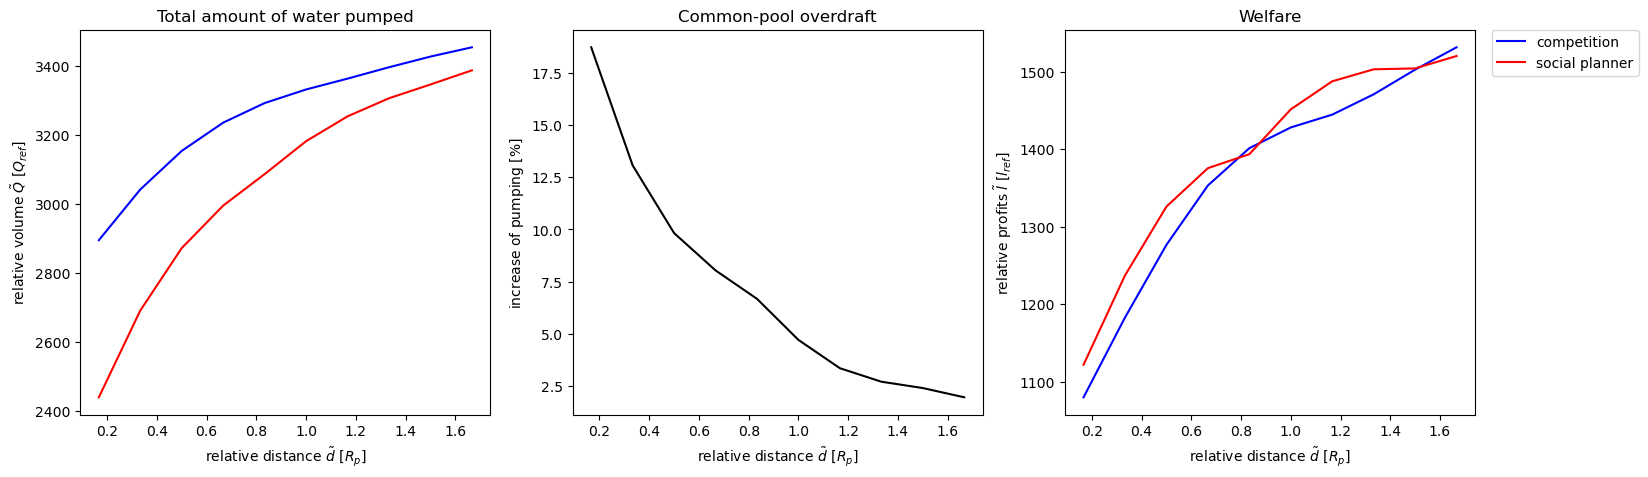

In [717]:
fig = plt.figure(figsize=(18,5))

# Water pumped
ax = fig.add_subplot(1, 3, 1)
ax.plot(distances, -RHG_water_pumped[:,-1], "b")
ax.plot(distances, -welfare_water_pumped[:,-1], "r")

ax.set_title("Total amount of water pumped")
ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_xlabel(r"relative distance $\tilde d$ [$R_p$]")

# Overdraft
ax = fig.add_subplot(1, 3, 2)
# ax.plot(distances, (RHG_water_pumped[:,-1] - welfare_water_pumped[:,-1]), "black")
ax.plot(distances, 100*(RHG_water_pumped[:,-1] - welfare_water_pumped[:,-1])/welfare_water_pumped[:,-1], "black")

ax.set_title("Common-pool overdraft")
# ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_ylabel(r"increase of pumping [$\%$]")
ax.set_xlabel(r"relative distance $\tilde d$ [$R_p$]")

# Welfare
ax2 = fig.add_subplot(1, 3, 3)
ax2.plot(distances, RHG_aggregated_welfare[:,-1]/alpha, "b", label = "competition")
ax2.plot(distances, welfare_aggregated_welfare[:,-1]/alpha, "r", label = "social planner")

ax2.set_title("Welfare")
ax2.set_ylabel(r"relative profits $\tilde l$ [$l_{ref}$]")
ax2.set_xlabel(r"relative distance $\tilde d$ [$R_p$]")

ax2.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# plt.savefig('../../Paper/figures/Fig3.svg', format='svg')
plt.show()

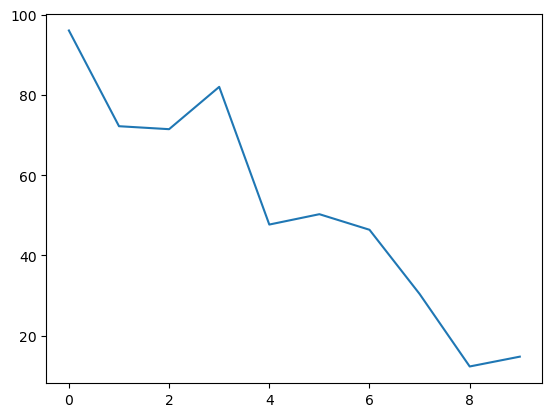

In [718]:
plt.plot(-(RHG_aggregated_welfare[:,-2]/alpha)+(welfare_aggregated_welfare[:,-2]/alpha))

Combining both dimensions allows us to evaluate the overdraft resulting from different forecast ability and spatial configuration.

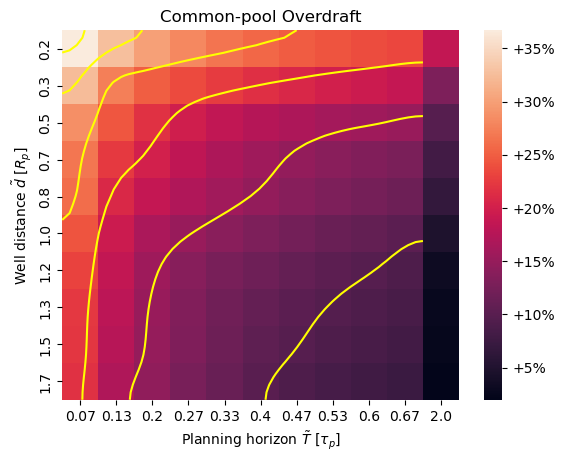

In [722]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_divergence[:,:-1].shape[1], RHG_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_divergence[:,:-1].shape[0], RHG_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1),
                cbar_kws={'format': '+%.0f%%'})

plt.title("Common-pool Overdraft")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

# plt.savefig('../../Paper/figures/Fig4.svg', format='svg')
plt.show()

# Dimensionless system -- Longer simulation + Cost inversion + Larger aquifer + Longer horizons

## Build Data

In [5]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [28]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_larger/long_horizon/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data['finite welfare'].keys():
        data['finite welfare'][rel_distance] = {}
    data['finite welfare'][rel_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for rel_distance in data['finite welfare'].keys():
    data['infinite welfare'][rel_distance] = data['finite welfare'][rel_distance][45]

In [29]:
[(v,max(list(d.keys()))) for v, d in data['finite welfare'].items()]

[(np.float64(0.8), 45),
 (np.float64(0.4), 45),
 (np.float64(1.8), 45),
 (np.float64(0.6), 45),
 (np.float64(1.2), 45),
 (np.float64(0.2), 45),
 (np.float64(1.6), 45),
 (np.float64(2.0), 45),
 (np.float64(1.4), 45),
 (np.float64(1.0), 45)]

In [30]:
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_larger/long_horizon/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data['RHG'].keys():
        data['RHG'][rel_distance] = {}
    data['RHG'][rel_distance][horizon] = result_data['inputs']

## Display data

In [31]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [32]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

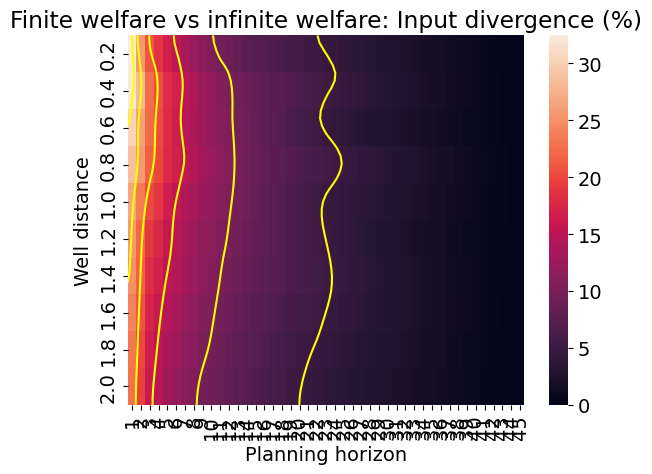

In [34]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, finite_infinite_divergence[:,:-1].shape[1], finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, finite_infinite_divergence[:,:-1].shape[0], finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [35]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(32.43810425981889), np.float64(32.164735005972126))

In [36]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

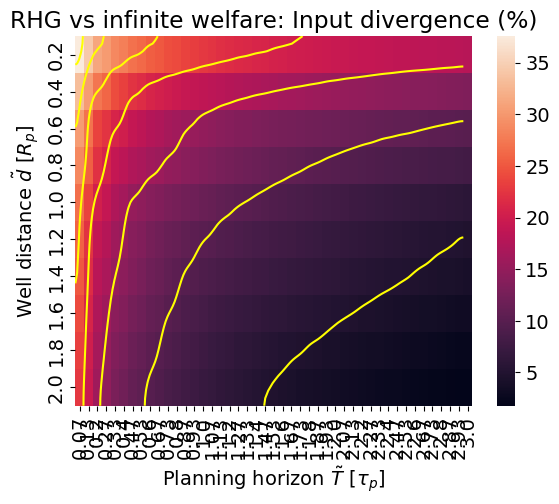

In [37]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_divergence[:,:-1].shape[1], RHG_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_divergence[:,:-1].shape[0], RHG_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

In [38]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(37.57818248193084), np.float64(1.7731994252527112))

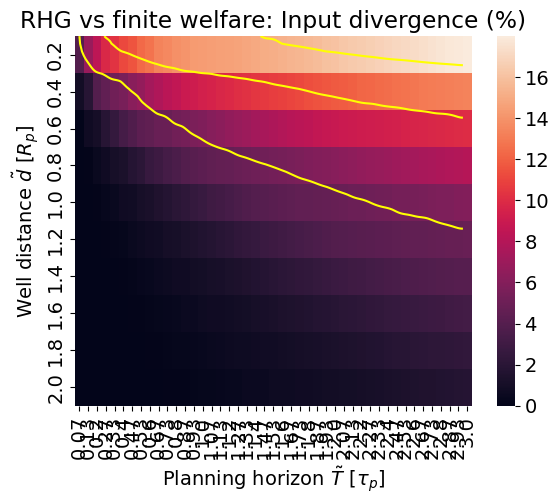

In [39]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_divergence[:,:-1].shape[1], RHG_finite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_divergence[:,:-1].shape[0], RHG_finite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

In [40]:
# RHG input divergence
RHG_finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['RHG'][distance][30] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['RHG'][distance][30], axis=0)
        RHG_finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

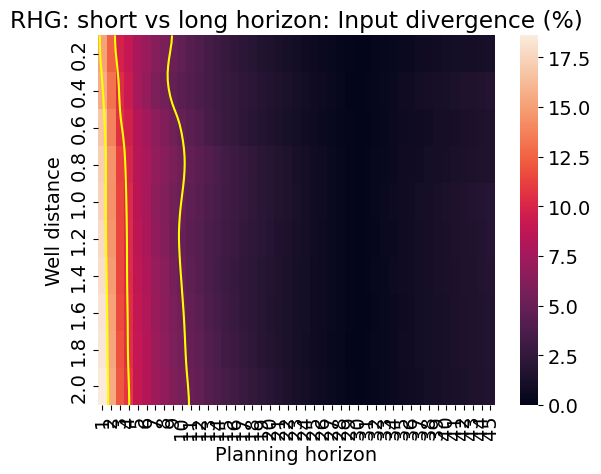

In [41]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_finite_infinite_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[1], RHG_finite_infinite_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_finite_infinite_divergence[:,:-1].shape[0], RHG_finite_infinite_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.round(1))

plt.title("RHG: short vs long horizon: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [42]:
cost_data = {'total': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}, \
             'pumping': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}, \
                'yield': {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}}
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless_longer_larger/long_horizon/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in cost_data['total']['finite welfare'].keys():
        cost_data['total']['finite welfare'][rel_distance] = {}
        cost_data['pumping']['finite welfare'][rel_distance] = {}
        cost_data['yield']['finite welfare'][rel_distance] = {}
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    # cost_heads = (result_data['h_wells'][:,1:] + result_data['h_wells'][:,:-1])/2
    cost_heads = result_data['h_wells'][:,1:] 
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = - alpha * result_data['q_rates'][:,:-1]
    cost_data['total']['finite welfare'][rel_distance][horizon] = pumping_cost + yield_profit
    cost_data['pumping']['finite welfare'][rel_distance][horizon] = pumping_cost
    cost_data['yield']['finite welfare'][rel_distance][horizon] = yield_profit

# Infinite Horizon Welfare
for rel_distance in cost_data['total']['finite welfare'].keys():
    cost_data['total']['infinite welfare'][rel_distance] = cost_data['total']['finite welfare'][rel_distance][30]
    cost_data['pumping']['infinite welfare'][rel_distance] = cost_data['pumping']['finite welfare'][rel_distance][30]
    cost_data['yield']['infinite welfare'][rel_distance] = cost_data['yield']['finite welfare'][rel_distance][30]

# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_larger/long_horizon/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in cost_data['total']['RHG'].keys():
        cost_data['total']['RHG'][rel_distance] = {}
        cost_data['pumping']['RHG'][rel_distance] = {}
        cost_data['yield']['RHG'][rel_distance] = {}
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    # cost_heads = (result_data['h_wells'][:,1:] + result_data['h_wells'][:,:-1])/2
    cost_heads = result_data['h_wells'][:,1:]
    profit = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1] - alpha * result_data['q_rates'][:,:-1]
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = -alpha * result_data['q_rates'][:,:-1]
    cost_data['total']['RHG'][rel_distance][horizon] = profit
    cost_data['pumping']['RHG'][rel_distance][horizon] = pumping_cost
    cost_data['yield']['RHG'][rel_distance][horizon] = yield_profit

In [43]:
# Game/welfare input divergence
RHG_infinite_cost_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        cost_distances = np.linalg.norm(
            cost_data['total']['infinite welfare'][distance] - cost_data['total']['RHG'][distance][horizon],
            axis=0)
        cost_divergences = cost_distances / np.linalg.norm(
            cost_data['total']['infinite welfare'][distance], axis=0)
        RHG_infinite_cost_divergence[d][h] = cost_divergences.sum()/cost_divergences.shape[0]

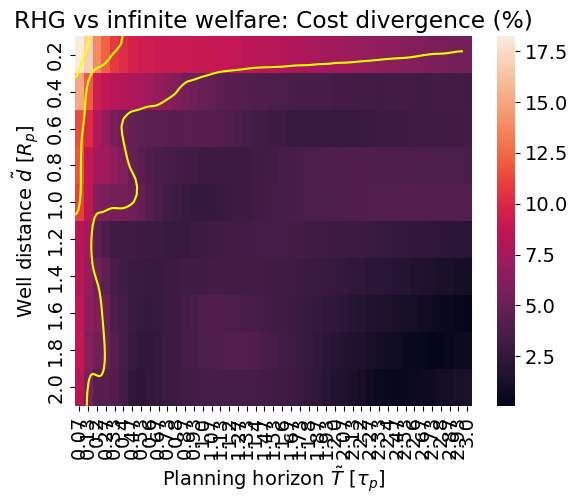

In [44]:
fig, ax = plt.subplots()

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_cost_divergence[:,:-1]*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_cost_divergence[:,:-1].shape[1], RHG_infinite_cost_divergence[:,:-1].shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_cost_divergence[:,:-1].shape[0], RHG_infinite_cost_divergence[:,:-1].shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

ax = seaborn.heatmap(RHG_infinite_cost_divergence*100,
                xticklabels=(horizons/param_data['dimensions']['tau_p']).round(2), yticklabels=distances.round(1))

plt.title("RHG vs infinite welfare: Cost divergence (%)")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

plt.show()

### Article figures V3

As expected, myopic self-interested players pump more than centralized social-planner. The excess of water pumped (due to competition and lack of anticipation) is called common-pool overdraft.

In [45]:
# Game/welfare water pumped
RHG_water_pumped = np.zeros((len(distances), len(horizons)))
welfare_water_pumped = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        RHG_water_pumped[d][h] = data['RHG'][distance][horizon].sum()
        welfare_water_pumped[d][h] = data['infinite welfare'][distance].sum()
# Game/welfare cost divergence
RHG_aggregated_welfare = np.zeros((len(distances), len(horizons)))
welfare_aggregated_welfare = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        RHG_aggregated_welfare[d][h] = cost_data['total']['RHG'][distance][horizon].sum()
        welfare_aggregated_welfare[d][h] = cost_data['total']['infinite welfare'][distance].sum()

In [46]:
result_data['pred_q_rates'].shape

(2, 5, 150)

In [47]:
# RHG planned policy
data_pred_q = {'RHG': {}}
directory = 'run_data/two_wells_analysis_dimless_longer_larger/long_horizon/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data_pred_q['RHG'].keys():
        data_pred_q['RHG'][rel_distance] = {}
    data_pred_q['RHG'][rel_distance][horizon] = result_data['pred_q_rates']

In [48]:
plt.rcParams.update({'font.size': 14})

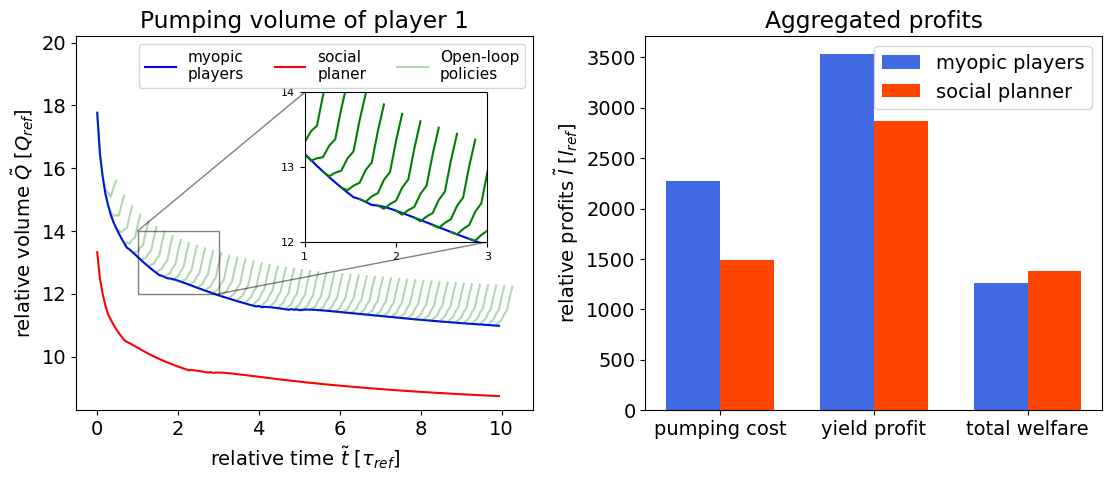

In [50]:
fig = plt.figure(figsize=(17,5))
ax = None
rel_times = np.arange(len(data['RHG'][distances[0]][1][:4,:].sum(axis=0)))/param_data['dimensions']['tau_p']
RHG_color = "blue"
welfare_color = "red"
hor = 7

# Player 1
ax = fig.add_subplot(1, 3, 1, sharey=ax)
ttl = f"Pumping volume of player 1"
ax.set_title(ttl)
ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_xlabel(r"relative time $\tilde t$ [$\tau_{ref}$]")
ax.plot(rel_times, -data['RHG'][distances[0]][horizons[hor]][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], RHG_color, label='myopic\nplayers')
ax.plot(rel_times, -data['infinite welfare'][distances[0]][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], welfare_color, label='social\nplaner')
# Display predicted evolution
future_q = data_pred_q['RHG'][distances[0]][horizons[hor]]
K = future_q.shape[1]
dt = np.linspace(0, K-1,  K)
for t0, q_pred in enumerate(np.rollaxis(future_q, 2)):
    if t0 % 3 == 0:
        t = (t0 + dt)/param_data['dimensions']['tau_p']
        ax.plot(t, -q_pred[0, :], color="green", alpha=0.3,
                label="Open-loop\npolicies" if t0==0 else None)


# inset Axes....
x1, x2, y1, y2 = 1, 3, 12, 14  # subregion of the original image
axins = ax.inset_axes(
    [0.5, 0.45, 0.4, 0.4],
    xlim=(x1, x2), ylim=(y1, y2), xticks=np.linspace(x1, x2, 3), yticks=np.linspace(y1, y2, 3))
axins.tick_params(axis='both', which='major', labelsize=8)
axins.plot(rel_times, -data['RHG'][distances[0]][horizons[hor]][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping'], RHG_color)
for t0, q_pred in enumerate(np.rollaxis(future_q, 2)):
    if t0 % 3 == 0:
        t = (t0 + dt)/param_data['dimensions']['tau_p']
        axins.plot(t, -q_pred[0, :], color="green", alpha=1,
                label="Open-loop\npolicies" if t0==0 else None)

ax.indicate_inset_zoom(axins, edgecolor="black")
y_min, y_max = ax.get_ylim()
ax.set_ylim(y_min, y_max+0.2*(y_max-y_min))
ax.legend(loc="upper right", ncol=3, fontsize=11)

# Profits
# ax = fig.add_subplot(1, 3, 2)
# ttl = f"Aggregated profits"
# ax.set_title(ttl)
# ax.set_ylabel(r"relative profits $\tilde l$ [$l_{ref}$]")
# ax.set_xlabel(r"relative time $\tilde t$ [$\tau_{ref}$]")
# ax.plot(rel_times[:-1], cost_data['pumping']['RHG'][distances[0]][horizons[hor]].sum(axis=0)/alpha, RHG_color, linestyle="--", label='myopic players')
# ax.plot(rel_times[:-1], cost_data['pumping']['infinite welfare'][distances[0]].sum(axis=0)/alpha, welfare_color, linestyle="--", label='social planer')
# ax.plot(rel_times[:-1], cost_data['yield']['RHG'][distances[0]][horizons[hor]].sum(axis=0)/alpha, RHG_color, linestyle="-.", label='myopic players')
# ax.plot(rel_times[:-1], cost_data['yield']['infinite welfare'][distances[0]].sum(axis=0)/alpha, welfare_color, linestyle="-.", label='social planer')
# ax.plot(rel_times[:-1], cost_data['total']['RHG'][distances[0]][horizons[hor]].sum(axis=0)/alpha, RHG_color, label='myopic players')
# ax.plot(rel_times[:-1], cost_data['total']['infinite welfare'][distances[0]].sum(axis=0)/alpha, welfare_color, label='social planer')

# legend_elements = [mlines.Line2D([0], [0], color='black', linestyle="-.", lw=1, label='yield profit'),
#                    mlines.Line2D([0], [0], color='black', linestyle="--", lw=1, label='pumping cost'),
#                    mlines.Line2D([0], [0], color='black', linestyle="-", lw=1, label='aggregated welfare')]
# ax.legend(handles=legend_elements)

# # Custom legend
# legend_elements = [mlines.Line2D([0], [0], color=RHG_color, lw=4, label='myopic players'),
#                    mlines.Line2D([0], [0], color=welfare_color, lw=4, label='social planer'),
#                    mlines.Line2D([0], [0], color='black', linestyle="-.", lw=1, label='yield profit'),
#                    mlines.Line2D([0], [0], color='black', linestyle="--", lw=1, label='pumping cost'),
#                    mlines.Line2D([0], [0], color='black', linestyle="-", lw=1, label='aggregated profit')]
# ax.legend(handles=legend_elements, bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# ax = fig.add_subplot(2, 2, 3)
# ttl = f"Common-pool overdraft"
# ax.set_title(ttl)
# ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
# ax.set_xlabel(r"relative time $\tilde t$ [$\tau_p$]")
# overdraft = (-data['RHG'][distances[0]][1][:,:].sum(axis=0) \
#         + data['finite welfare'][distances[0]][30][:,:].sum(axis=0))\
#                  /param_data['dimensions']['reference_pumping']
# ax.plot(rel_times, (overdraft), "blue")

# plt.savefig('../../Paper/figures/Fig1.svg', format='svg')

# Aggregated profits
ax = fig.add_subplot(1, 3, 2)
ttl = f"Aggregated profits"
ax.set_title(ttl)
ax.set_ylabel(r"relative profits $\tilde l$ [$l_{ref}$]")

cost_type = ("pumping cost", "yield profit", "total welfare")
costs = {
    'myopic players': ((-cost_data['pumping']['RHG'][distances[0]][horizons[hor]].sum(axis=0)/alpha).sum(), (cost_data['yield']['RHG'][distances[0]][horizons[hor]].sum(axis=0)/alpha).sum(), (cost_data['total']['RHG'][distances[0]][horizons[hor]].sum(axis=0)/alpha).sum()),
    'social planner': ((-cost_data['pumping']['infinite welfare'][distances[0]].sum(axis=0)/alpha).sum(), (cost_data['yield']['infinite welfare'][distances[0]].sum(axis=0)/alpha).sum(), (cost_data['total']['infinite welfare'][distances[0]].sum(axis=0)/alpha).sum())
}

x = np.arange(len(cost_type))  # label locations
width = 0.35  # width of the bars
bars1 = ax.bar(x - width/2, costs["myopic players"], width, label='myopic players', color="royalblue")
bars2 = ax.bar(x + width/2, costs["social planner"], width, label='social planner', color="orangered")
ax.set_xticks(x)
ax.set_xticklabels(cost_type)

ax.legend()

fig.tight_layout(pad=1)

plt.show()

In [51]:
(costs["myopic players"][2] - costs["social planner"][2])/costs["social planner"][2]

np.float64(-0.08603624837142039)

In [53]:
((data['RHG'][distances[0]][horizons[hor]][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping']).sum() - (data['infinite welfare'][distances[0]][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping']).sum())/(data['infinite welfare'][distances[0]][:4,:].sum(axis=0)/param_data['dimensions']['reference_pumping']).sum()

np.float64(0.26406063830702964)

When progressively increasing the horizon, overdraft reduce and welfare increases and get closer to social optimum (baseline)

In [26]:
(data['RHG'][distances[0]][horizons[hor]][:4,:].sum(axis=0).sum() - data['finite welfare'][distances[0]][30][:4,:].sum(axis=0).sum())/data['RHG'][distances[0]][horizons[hor]][:4,:].sum(axis=0).sum()

np.float64(0.18611512607981884)

In [27]:
(cost_data['total']['RHG'][distances[0]][horizons[hor]].sum(axis=0) - cost_data['total']['infinite welfare'][distances[0]].sum(axis=0)).sum()/cost_data['total']['RHG'][distances[0]][horizons[hor]].sum(axis=0).sum()

np.float64(-0.0941352960859921)

##### Turnpike effect

In [28]:
directory = 'run_data/two_wells_analysis_dimless_longer_larger/long_horizon/RHG'
# Initialize Model
dist = distances[3]
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
    if rel_distance == dist:
        parameter_file = os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')
        break
param_handler = DimensionlessParameterInterface(parameter_file)
model = IrrigationSchedulingModel(param_handler, boundary_condition="Constant Head")
cost = IrrigationSchedulingCostLinearYield(param_handler, model)

/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/ParameterInterface/DimensionlessParameterInterface.py:87: RuntimeWarning: divide by zero encountered in divide
  inv_ETmax_c_t = np.where(self.ETmax_c_t !=0, 1/self.ETmax_c_t, 0)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.9/site-packages/scipy/sparse/_index.py:151: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


In [29]:
# K_range = [5]+list(range(10,110,10))

# policy = []
# traj = []
# for K in K_range:
#     # Initialize Controller
#     controller = TimeVaryingCost_LQRc_RHG(
#         param_handler,
#         model.A, model.B_v, model.C,
#         model.H_x, model.h_x, model.H_u_v, model.h_u_v,
#         model.H_xu_x, model.H_xu_u, model.h_xu,
#         solver='fbrs',
#         overwrite_time_horizon=K
#     )
#     Q, R, R_minus, M, L = cost.get_cost_matrices(0, controller.K)
#     controller.update_cost_matrices(Q, R, R_minus, M, L)
#     inputs, x_pred = controller.step(sp.lil_array(model.state-30))
#     policy.append(inputs)
#     traj.append(model.select_wells(x_pred))

In [30]:
# fig_q = plt.figure(figsize=(10,5))
# ax_q = None
# ax_q = fig_q.add_subplot(1, 2, 1, sharey=ax_q)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("pumping volume")
# for k, K in enumerate(K_range):
#     t = np.linspace(0,K, K+1)
#     ax_q.plot(-policy[k][:,:4].sum(axis=1), "b.-")
#     #ax_q.plot(-policy[k][:,:4].sum(axis=1) + (1/model.heads_correction)*np.linspace(0,policy[k].shape[0]-1,policy[k].shape[0]), "b.-")
    
    
# ax_q = fig_q.add_subplot(1, 2, 2)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("heads")
# for k, K in enumerate(K_range):
#     t = np.linspace(0,K, K+1)
#     # ax_q.plot(traj[k][0,:], "b.-")
#     ax_q.plot(model.apply_head_correction(traj[k][0,1:], policy[k][:,:4].sum(axis=1)), "b.-")

In [31]:
nx = model.A.shape[0]
nu = sum([model.B_v[v].shape[1] for v in range(model.n_agent)])
# Equilibrium state
_, R_v, R_vm, M_v, L_v = cost.get_cost_matrices(1,1)
# Construct new Gamma and Xi matrices
I_A_inv = np.linalg.inv(np.eye(nx)-model.A)
B = np.hstack([B.toarray() for B in model.B_v])
R = [np.vstack([R_v[0][0], R_vm[1][0].toarray()]), np.vstack([R_vm[0][0].toarray(), R_v[1][0]])]
Gamma_v_tilde = [(I_A_inv@B).T @ M_v[v][0] + R[v]\
                for v in range(model.n_agent)]
Xi_v_tilde = [(I_A_inv@model.C).T @ M[0] + L[0]  for M, L in zip(M_v,L_v)]
# Construct cost matrices
F = sp.block_diag([Gamma_v_tilde[v][sum(model.nu_v[:v]): sum(model.nu_v[:v+1])].T \
                    for v in range(model.n_agent)]).toarray()
F += np.vstack([Gamma.T for Gamma in Gamma_v_tilde])
f = np.vstack([Xi.T for Xi in Xi_v_tilde])
# Construct constraint matrices
H = np.vstack([
    sp.block_diag(model.H_u_v).toarray()#,
    # model.H_x @ I_A_inv @ B
])
h = np.vstack([
    sp.vstack(model.h_u_v).toarray()#,
    # model.h_x.toarray() - I_A_inv @ model.C
])
# Find equilibrium
u_s_0 = 0*np.ones((nu, 1))
dual_0 = np.zeros((H.shape[0], 1))
u_s, dual, E, out = fbrs(F, f, H, h, u_s_0, dual_0)
x_s = I_A_inv @ (B @ u_s + model.C)

In [32]:
u_s[0,0], u_s[4,0], model.apply_head_correction(model.select_wells(x_s), u_s[[0,4],:])

(np.float64(-10.06299438309048),
 np.float64(-10.073877547057277),
 array([[27.11049932],
        [27.11722207]]))

In [33]:
# fig = plt.figure(figsize=(10,5))
# ax = fig.add_subplot(1, 2, 2)
# ttl = f"Open loop trajectories"
# ax.set_title(ttl)
# ax.set_xlabel(r"relative time $\tilde t$ [$\tau_{ref}$]")
# ax.set_ylabel(r"relative heads $\tilde h$ [$d_{ref}$]")
# ax.axhline(model.apply_head_correction(model.select_wells(x_s)[0], u_s[0,0]), 0, K_range[0], color="r", linestyle="--")
# for k, K in enumerate(K_range):
#     t = np.linspace(0,K, K+1)
#     ax.plot(traj[k][0,:], "c-")
# legend_elements = [mlines.Line2D([0], [0], color="cyan", label='Open loop'),
#                    mlines.Line2D([0], [0], color="red", linestyle="--", label=r'$\tilde{h}_s$')]
# ax.legend(handles=legend_elements)

Very long horizon exploration

In [34]:
# K_range_long = [5]+list(range(50,151,50))

# policy_long = []
# traj_long = []
# for K in K_range_long:
#     # Initialize Controller
#     controller = TimeVaryingCost_LQRc_RHG(
#         param_handler,
#         model.A, model.B_v, model.C,
#         model.H_x, model.h_x, model.H_u_v, model.h_u_v,
#         model.H_xu_x, model.H_xu_u, model.h_xu,
#         solver='fbrs',
#         overwrite_time_horizon=K
#     )
#     Q, R, R_minus, M, L = cost.get_cost_matrices(0, controller.K)
#     controller.update_cost_matrices(Q, R, R_minus, M, L)
#     inputs, x_pred = controller.step(sp.lil_array(model.state-30))
#     policy_long.append(inputs)
#     traj_long.append(model.select_wells(x_pred))

In [35]:
# fig_q = plt.figure(figsize=(10,5))
# ax_q = None
# ax_q = fig_q.add_subplot(1, 2, 1, sharey=ax_q)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("pumping volume")
# for k, K in enumerate(K_range_long):
#     t = np.linspace(0,K, K+1)
#     ax_q.plot(-policy_long[k][:,:4].sum(axis=1), "b.-")
#     #ax_q.plot(-policy_long[k][:,:4].sum(axis=1) + (1/model.heads_correction)*np.linspace(0,policy_long[k].shape[0]-1,policy_long[k].shape[0]), "b.-")
    
    
# ax_q = fig_q.add_subplot(1, 2, 2)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("heads")
# for k, K in enumerate(K_range_long):
#     t = np.linspace(0,K, K+1)
#     ax_q.plot(traj_long[k][0,:], "b.-")
#     ax_q.plot(model.apply_head_correction(traj_long[k][0,:-1], policy_long[k][:,:4].sum(axis=1)), "c.-")

In [36]:
controller = TimeVaryingCost_LQRc_RHG(
    param_handler,
    model.A, model.B_v, model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs',
    overwrite_time_horizon=10
)
# Q, R, R_minus, M, L = cost.get_cost_matrices(0, controller.K)
# controller.update_cost_matrices(Q, R, R_minus, M, L)
# controller.step(sp.lil_array(model.state-30))

In [37]:
# policy_test = np.zeros((controller.K*model.n_agent*4, 1))
# policy_test[:controller.K*4:4] = u_s[0,0]
# policy_test[controller.K*4::4] = u_s[4,0]
# traj_test = model.select_wells(controller._apply_commands(x_s, policy_test))

In [38]:
# fig_q = plt.figure(figsize=(10,5))
# ax_q = None
# ax_q = fig_q.add_subplot(1, 2, 1, sharey=ax_q)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("pumping volume")
# K=5
# t = np.linspace(0,K, K+1)
# ax_q.plot(-controller._solution_to_command(policy_test)[:,:4].sum(axis=1), "b.-")
# #ax_q.plot(-controller._solution_to_command(policy_test)[:,:4].sum(axis=1) + (1/model.heads_correction)*np.linspace(0,controller._solution_to_command(policy_test).shape[0]-1,controller._solution_to_command(policy_test).shape[0]), "b.-")
    
    
# ax_q = fig_q.add_subplot(1, 2, 2)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("heads")
# K=5
# t = np.linspace(0,K, K+1)
# ax_q.plot(traj_test[0,:], "b.-")
# ax_q.plot(model.apply_head_correction(traj_test[0,1:], controller._solution_to_command(policy_test)[:,:4].sum(axis=1)), "c.-")

In [39]:
# K_range_long = [5]+list(range(50,151,50))

# policy_from_x_s = []
# traj_from_x_s = []
# for K in K_range_long:
#     # Initialize Controller
#     controller = TimeVaryingCost_LQRc_RHG(
#         param_handler,
#         model.A, model.B_v, model.C,
#         model.H_x, model.h_x, model.H_u_v, model.h_u_v,
#         model.H_xu_x, model.H_xu_u, model.h_xu,
#         solver='fbrs',
#         overwrite_time_horizon=K
#     )
#     Q, R, R_minus, M, L = cost.get_cost_matrices(0, controller.K)
#     controller.update_cost_matrices(Q, R, R_minus, M, L)
#     inputs, x_pred = controller.step(sp.lil_array(x_s+5))
#     policy_from_x_s.append(inputs)
#     traj_from_x_s.append(model.select_wells(x_pred))

In [40]:
# fig_q = plt.figure(figsize=(10,5))
# ax_q = None
# ax_q = fig_q.add_subplot(1, 2, 1, sharey=ax_q)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("pumping volume")
# for k, K in enumerate(K_range_long):
#     t = np.linspace(0,K, K+1)
#     ax_q.plot(-policy_from_x_s[k][:,:4].sum(axis=1), "b.-")
#     #ax_q.plot(-policy_from_x_s[k][:,:4].sum(axis=1) + (1/model.heads_correction)*np.linspace(0,policy_from_x_s[k].shape[0]-1,policy_from_x_s[k].shape[0]), "b.-")
    
    
# ax_q = fig_q.add_subplot(1, 2, 2)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("heads")
# for k, K in enumerate(K_range_long):
#     t = np.linspace(0,K, K+1)
#     ax_q.plot(traj_from_x_s[k][0,:], "b.-")
#     ax_q.plot(model.apply_head_correction(traj_from_x_s[k][0,:-1], policy_from_x_s[k][:,:4].sum(axis=1)), "c.-")

In [41]:
# K_range_long = [5]+list(range(50,151,50))

# policy_closer_from_x_s = []
# traj_closer_from_x_s = []
# for K in K_range_long:
#     # Initialize Controller
#     controller = TimeVaryingCost_LQRc_RHG(
#         param_handler,
#         model.A, model.B_v, model.C,
#         model.H_x, model.h_x, model.H_u_v, model.h_u_v,
#         model.H_xu_x, model.H_xu_u, model.h_xu,
#         solver='fbrs',
#         overwrite_time_horizon=K
#     )
#     Q, R, R_minus, M, L = cost.get_cost_matrices(0, controller.K)
#     controller.update_cost_matrices(Q, R, R_minus, M, L)
#     inputs, x_pred = controller.step(sp.lil_array(x_s+2))
#     policy_closer_from_x_s.append(inputs)
#     traj_closer_from_x_s.append(model.select_wells(x_pred))

In [42]:
# fig_q = plt.figure(figsize=(10,5))
# ax_q = None
# ax_q = fig_q.add_subplot(1, 2, 1, sharey=ax_q)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("pumping volume")
# for k, K in enumerate(K_range_long):
#     t = np.linspace(0,K, K+1)
#     ax_q.plot(-policy_closer_from_x_s[k][:,:4].sum(axis=1), "b.-")
#     #ax_q.plot(-policy_closer_from_x_s[k][:,:4].sum(axis=1) + (1/model.heads_correction)*np.linspace(0,policy_closer_from_x_s[k].shape[0]-1,policy_closer_from_x_s[k].shape[0]), "b.-")
    
    
# ax_q = fig_q.add_subplot(1, 2, 2)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("heads")
# for k, K in enumerate(K_range_long):
#     t = np.linspace(0,K, K+1)
#     ax_q.plot(traj_closer_from_x_s[k][0,:], "b.-")
#     ax_q.plot(model.apply_head_correction(traj_closer_from_x_s[k][0,:-1], policy_closer_from_x_s[k][:,:4].sum(axis=1)), "c.-")

In [43]:
# K_range_long = [5]+list(range(50,150,50))

# policy_further_from_x_s = []
# traj_further_from_x_s = []
# for K in K_range_long:
#     # Initialize Controller
#     controller = TimeVaryingCost_LQRc_RHG(
#         param_handler,
#         model.A, model.B_v, model.C,
#         model.H_x, model.h_x, model.H_u_v, model.h_u_v,
#         model.H_xu_x, model.H_xu_u, model.h_xu,
#         solver='fbrs',
#         overwrite_time_horizon=K
#     )
#     Q, R, R_minus, M, L = cost.get_cost_matrices(0, controller.K)
#     controller.update_cost_matrices(Q, R, R_minus, M, L)
#     inputs, x_pred = controller.step(sp.lil_array(x_s+15))
#     policy_further_from_x_s.append(inputs)
#     traj_further_from_x_s.append(model.select_wells(x_pred))

In [44]:
# fig_q = plt.figure(figsize=(10,5))
# ax_q = None
# ax_q = fig_q.add_subplot(1, 2, 1, sharey=ax_q)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("pumping volume")
# for k, K in enumerate(K_range_long):
#     t = np.linspace(0,K, K+1)
#     ax_q.plot(-policy_further_from_x_s[k][:,:4].sum(axis=1), "b.-")
#     #ax_q.plot(-policy_further_from_x_s[k][:,:4].sum(axis=1) + (1/model.heads_correction)*np.linspace(0,policy_further_from_x_s[k].shape[0]-1,policy_further_from_x_s[k].shape[0]), "r.-")


# ax_q = fig_q.add_subplot(1, 2, 2)
# # ttl = f"Head at well ({ii})"
# # ax_h.set_title(ttl)
# ax_q.set_xlabel("time")
# ax_q.set_ylabel("heads")
# for k, K in enumerate(K_range_long):
#     t = np.linspace(0,K, K+1)
#     ax_q.plot(traj_further_from_x_s[k][0,:], "b.-")
#     ax_q.plot(model.apply_head_correction(traj_further_from_x_s[k][0,:-1], policy_further_from_x_s[k][:,:4].sum(axis=1)), "c.-")

In [45]:
# K_range_long = [5]+list(range(50,151,50))
K_range_long = [5]+list(range(10,110,10))

policy_multiple_of_x_s = []
traj_multiple_of_x_s = []
for K in K_range_long:
    # Initialize Controller
    controller = TimeVaryingCost_LQRc_RHG(
        param_handler,
        model.A, model.B_v, model.C,
        model.H_x, model.h_x, model.H_u_v, model.h_u_v,
        model.H_xu_x, model.H_xu_u, model.h_xu,
        solver='fbrs',
        overwrite_time_horizon=K
    )
    Q, R, R_minus, M, L = cost.get_cost_matrices(0, controller.K)
    controller.update_cost_matrices(Q, R, R_minus, M, L)
    inputs, x_pred = controller.step(sp.lil_array(x_s*0.5 + 35))
    policy_multiple_of_x_s.append(inputs)
    traj_multiple_of_x_s.append(model.select_wells(x_pred))

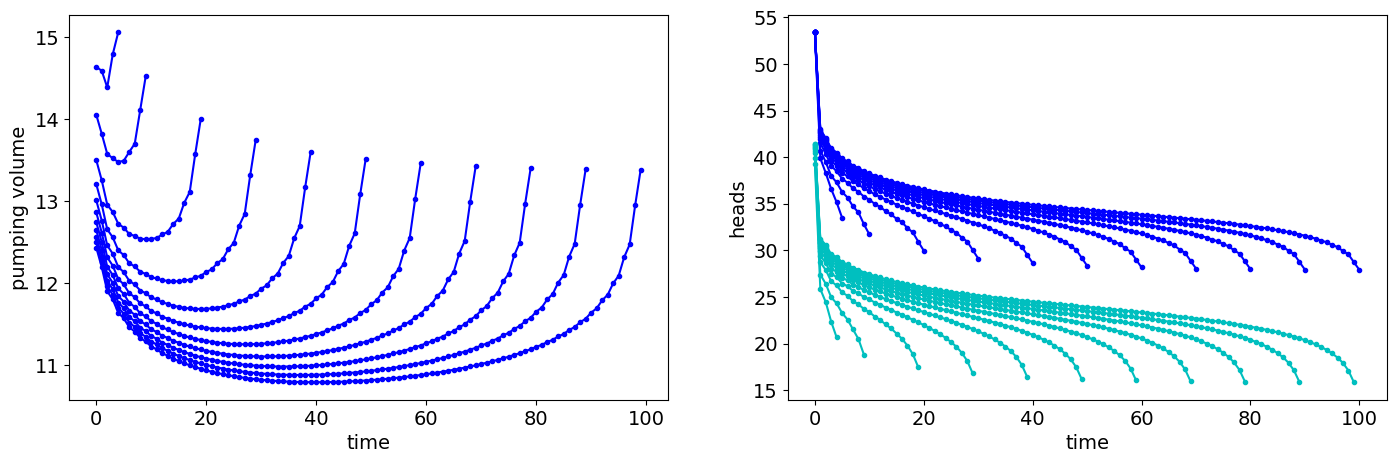

In [58]:
fig_q = plt.figure(figsize=(10,5))
ax_q = None
ax_q = fig_q.add_subplot(1, 2, 1, sharey=ax_q)
# ttl = f"Head at well ({ii})"
# ax_h.set_title(ttl)
ax_q.set_xlabel("time")
ax_q.set_ylabel("pumping volume")
for k, K in enumerate(K_range_long):
    t = np.linspace(0,K, K+1)
    ax_q.plot(-policy_multiple_of_x_s[k][:,:4].sum(axis=1), "b.-")
    #ax_q.plot(-policy_multiple_of_x_s[k][:,:4].sum(axis=1) + (1/model.heads_correction)*np.linspace(0,policy_multiple_of_x_s[k].shape[0]-1,policy_multiple_of_x_s[k].shape[0]), "r.-")


ax_q = fig_q.add_subplot(1, 2, 2)
# ttl = f"Head at well ({ii})"
# ax_h.set_title(ttl)
ax_q.set_xlabel("time")
ax_q.set_ylabel("heads")
for k, K in enumerate(K_range_long):
    t = np.linspace(0,K, K+1)
    ax_q.plot(traj_multiple_of_x_s[k][0,:], "b.-")
    ax_q.plot(model.apply_head_correction(traj_multiple_of_x_s[k][0,:-1], policy_multiple_of_x_s[k][:,:4].sum(axis=1)), "c.-")

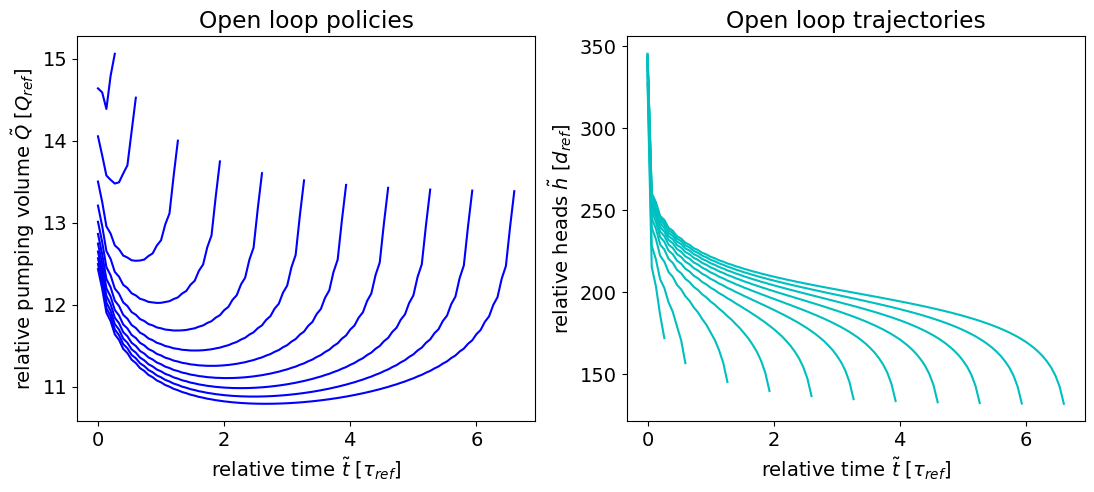

In [67]:
fig_q = plt.figure(figsize=(13,5))
ax_q = None
ax_q = fig_q.add_subplot(1, 2, 1, sharey=ax_q)
ttl = f"Open loop policies"
ax_q.set_title(ttl)
ax_q.set_xlabel(r"relative time $\tilde t$ [$\tau_{ref}$]")
ax_q.set_ylabel(r"relative pumping volume $\tilde Q$ [$Q_{ref}$]")
for k, K in enumerate(K_range_long):
    t = np.linspace(0,K-1, K)
    ax_q.plot(t/param_data['dimensions']['tau_p'], -policy_multiple_of_x_s[k][:,:4].sum(axis=1)/param_data['dimensions']['reference_pumping'], "b-")
    #ax_q.plot(-policy_multiple_of_x_s[k][:,:4].sum(axis=1) + (1/model.heads_correction)*np.linspace(0,policy_multiple_of_x_s[k].shape[0]-1,policy_multiple_of_x_s[k].shape[0]), "r.-")


ax_q = fig_q.add_subplot(1, 2, 2)
ttl = f"Open loop trajectories"
ax_q.set_title(ttl)
ax_q.set_xlabel(r"relative time $\tilde t$ [$\tau_{ref}$]")
ax_q.set_ylabel(r"relative heads $\tilde h$ [$d_{ref}$]")
for k, K in enumerate(K_range_long):
    t = np.linspace(0,K-1, K)
    ax_q.plot(t/param_data['dimensions']['tau_p'], (model.apply_head_correction(traj_multiple_of_x_s[k][0,:-1], policy_multiple_of_x_s[k][:,:4].sum(axis=1)))/param_handler.depth_p, "c-")
    

fig.tight_layout(pad=1)
plt.show()

In [48]:
data_h = {'RHG': {}}
# RHG
directory = 'run_data/two_wells_analysis_dimless_longer_larger/long_horizon/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not rel_distance in data_h['RHG'].keys():
        data_h['RHG'][rel_distance] = {}
    data_h['RHG'][rel_distance][horizon] = result_data['corrected_h_wells']

In [49]:
# Convergence of closed-loop trajectories to x_s
x_s_corr = model.apply_head_correction(model.select_wells(x_s)[0], u_s[0,0])
CL_heads = []
for hor in horizons:
    CL_heads.append(np.average(data_h['RHG'][distances[0]][hor][0,-10:]))

[]

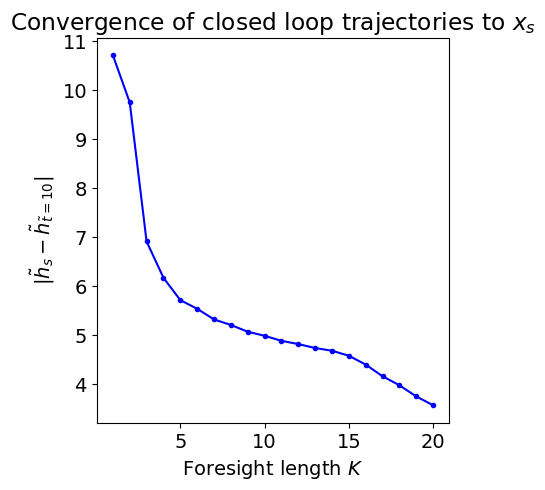

In [50]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 2, 2)
ttl = f"Convergence of closed loop trajectories to $x_s$"
ax.set_title(ttl)
ax.set_xlabel(r"Foresight length $K$")
ax.set_ylabel(r"$|\tilde{h}_s - \tilde{h}_{\tilde{t}=10}|$")
ax.plot(horizons[:-1], (x_s_corr-CL_heads)[:-1], "b.-")
ax.plot()

In [67]:
# Merge sort discarding duplicates
def merge_sort_unique(a, b, order=None):
    if order is None:
        order = (a, b)
    (order_a, order_b) = order
    sorted_a = np.argsort(order_a)
    sorted_b = np.argsort(order_b)
    a = np.array(a)[sorted_a]
    b = np.array(b)[sorted_b]
    order_a = np.array(order_a)[sorted_a]
    order_b = np.array(order_b)[sorted_b]
    merged = []
    i = j = 0
    while i < len(a) and j < len(b):
        if order_a[i] < order_b[j]:
            merged.append(a[i])
            i += 1
        elif order_a[i] > order_b[j]:
            merged.append(b[j])
            j += 1
        else:
            merged.append(a[i])
            i += 1
            j += 1
    while i < len(a):
        merged.append(a[i])
        i += 1
    while j < len(b):
        merged.append(b[j])
        j += 1
    return np.array(merged)

In [70]:
# Additional overdraft for longer horizons
directory = 'run_data/two_wells_analysis_dimless_longer_larger/long_horizon/additional_data/finite_welfare'
welfare_pumping = []
welfare_cost = []
welfare_horizons = []
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    welfare_pumping.append(result_data['inputs'].sum())
    welfare_horizons.append(horizon)
    # Cost
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    cost_heads = result_data['h_wells'][:,:-1] 
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = - alpha * result_data['q_rates'][:,:-1]
    welfare_cost.append((pumping_cost + yield_profit).sum())
    

welfare_horizons_argsort = np.argsort(welfare_horizons)
welfare_pumping = np.array(welfare_pumping)[welfare_horizons_argsort]
welfare_cost = np.array(welfare_cost)[welfare_horizons_argsort]
welfare_horizons = np.array(welfare_horizons)[welfare_horizons_argsort]

directory = 'run_data/two_wells_analysis_dimless_longer_larger/long_horizon/additional_data/RHG'
RHG_pumping = []
RHG_cost = []
RHG_final_heads = []
RHG_horizons = []
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        R_p = param_data['dimensions']['R_p']
        rel_distance = well_distance/R_p
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    RHG_pumping.append(result_data['inputs'].sum())
    RHG_horizons.append(horizon)
    # Cost
    alpha = param_data['costs']['selling_crop_price'][0] * (param_data['crops']['corn']['Y_max_t'][0]/ (param_data['crops']['corn']['Kc_t'][0]*param_data['physical']['ET0']))
    cost_heads = result_data['h_wells'][:,1:] 
    pumping_cost = param_data['costs']['extraction_cost'][0] * (10-cost_heads) * result_data['q_rates'][:,:-1]
    yield_profit = - alpha * result_data['q_rates'][:,:-1]
    RHG_cost.append((pumping_cost + yield_profit).sum())
    # heads
    RHG_final_heads.append(result_data['corrected_h_wells'][0,-10:].mean())

RHG_horizons_argsort = np.argsort(RHG_horizons)
RHG_pumping = np.array(RHG_pumping)[RHG_horizons_argsort]
RHG_cost = np.array(RHG_cost)[RHG_horizons_argsort]
RHG_final_heads = np.array(RHG_final_heads)[RHG_horizons_argsort]
RHG_horizons = np.array(RHG_horizons)[RHG_horizons_argsort]

original_horizons = sorted(list(data['finite welfare'][distances[0]].keys()))
horizons_extended = merge_sort_unique(original_horizons, RHG_horizons)
# np.hstack((np.sort(list(data['finite welfare'][distances[0]].keys())), RHG_horizons))
# arg_horizons = np.argsort(horizons_extended)
# horizons_extended = np.array(horizons_extended)[arg_horizons]
RHG_water_pumped_extended = merge_sort_unique(RHG_water_pumped[0,:], RHG_pumping, order=(original_horizons, RHG_horizons))
welfare_water_pumped_extended = merge_sort_unique(welfare_water_pumped[0,:], welfare_pumping, order=(original_horizons, welfare_horizons))
RHG_cost_extended = merge_sort_unique(RHG_aggregated_welfare[0,:], RHG_cost, order=(original_horizons, RHG_horizons))
welfare_cost_extended = merge_sort_unique(welfare_aggregated_welfare[0,:], welfare_cost, order=(original_horizons, welfare_horizons))

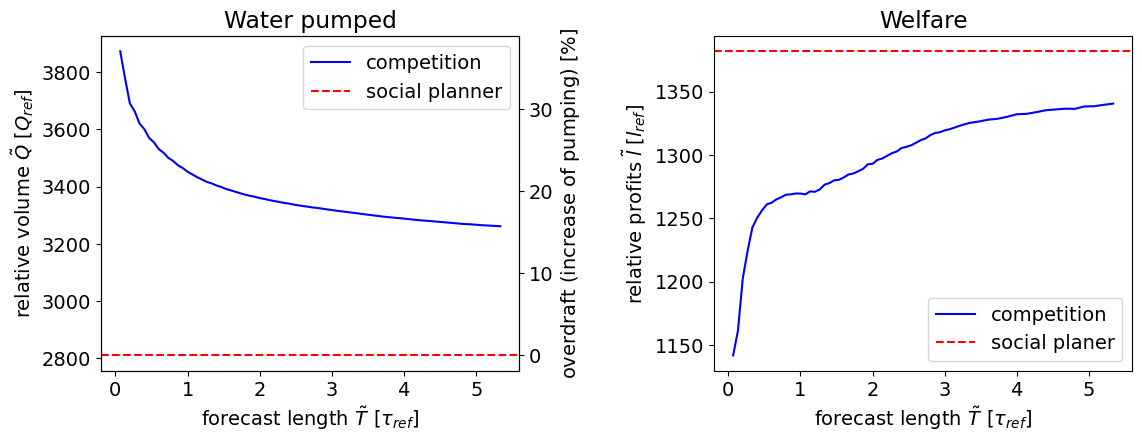

In [82]:
fig = plt.figure(figsize=(12,5))

max_welfare_water_pumped = max(-welfare_water_pumped_extended)

# Water pumped
ax = fig.add_subplot(1, 2, 1)
ax.plot(horizons_extended/param_data['dimensions']['tau_p'], -RHG_water_pumped_extended, "b", label='competition')
ax.axhline(max_welfare_water_pumped, color="r", linestyle="--", label='social planner')

ax.set_title("Water pumped")
ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_xlabel(r"forecast length $\tilde T$ [$\tau_{ref}$]")
y_q_min, y_q_max = ax.get_ylim()


# Overdraft
ax = ax.twinx()
# ax.plot(horizons_extended/param_data['dimensions']['tau_p'], -np.hstack((RHG_water_pumped[0,:], RHG_pumping))[arg_horizons] + min(np.hstack((welfare_water_pumped[0,:], welfare_pumping))), "black")
ax.plot(horizons_extended/param_data['dimensions']['tau_p'],\
    100*(RHG_water_pumped_extended + max_welfare_water_pumped)/ (-max_welfare_water_pumped),
            "black", alpha=0, label='Common-pool\noverdraft')
y_min, y_max = ax.get_ylim()
new_y_min = y_max * (y_q_min - max_welfare_water_pumped) / (y_q_max - max_welfare_water_pumped)
ax.set_ylim(new_y_min, y_max)

# ax.set_title("Common-pool overdraft")
# ax.set_ylabel(r"relative volume $\tilde Q$ [$Q_{ref}$]")
ax.set_ylabel(r"overdraft (increase of pumping) [$\%$]")
# ax.set_xlabel(r"forecast length $\tilde T$ [$\tau_{ref}$]")
legend_elements = [mlines.Line2D([0], [0], color="blue", label='competition'),
                   mlines.Line2D([0], [0], color="red", linestyle="--", label='social planner')]
                   #mlines.Line2D([0], [0], color="black", label='common-pool\noverdraft')]
ax.legend(handles=legend_elements)

# Welfare
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(horizons_extended/param_data['dimensions']['tau_p'], \
    RHG_cost_extended/alpha, "b", label='competition')
ax2.axhline(max(welfare_cost_extended/alpha),
            color="r", linestyle="--", label='social planer')

ax2.set_title("Welfare")
ax2.set_ylabel(r"relative profits $\tilde l$ [$l_{ref}$]")
ax2.set_xlabel(r"forecast length $\tilde T$ [$\tau_{ref}$]")

ax2.legend(loc="lower right")#bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

fig.tight_layout(pad=2.0)

# plt.savefig('../../Paper/figures/Fig2.svg', format='svg')
plt.show()

In [102]:
overdraft = (100*(RHG_water_pumped_extended + max_welfare_water_pumped)/ (-max_welfare_water_pumped))
overdraft[0], overdraft[-1], overdraft[14]

(np.float64(37.775271606525635),
 np.float64(16.044669038222764),
 np.float64(22.81551496560001))

In [101]:
(horizons_extended/param_data['dimensions']['tau_p'])[14]

np.float64(1.0)

In [103]:
cost_decrease = (((RHG_cost_extended/alpha)-max(welfare_cost_extended/alpha))/max(welfare_cost_extended/alpha))
cost_decrease[0], cost_decrease[-1], cost_decrease[14]

(np.float64(-0.17391998955441954),
 np.float64(-0.029909547429040947),
 np.float64(-0.08137379214624187))

[]

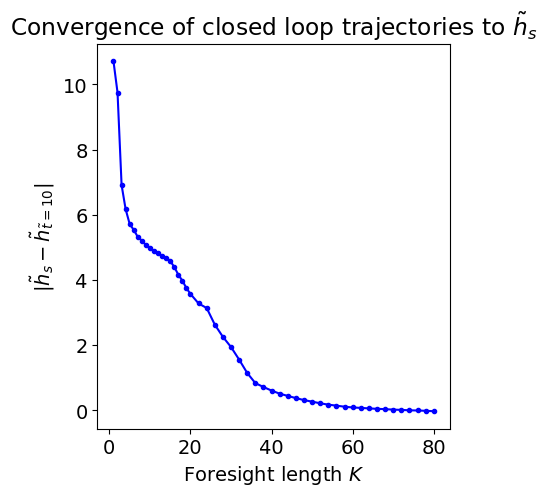

In [54]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(1, 2, 2)
ttl = r"Convergence of closed loop trajectories to $\tilde{h}_s$"
ax.set_title(ttl)
ax.set_xlabel(r"Foresight length $K$")
ax.set_ylabel(r"$|\tilde{h}_s - \tilde{h}_{\tilde{t}=10}|$")
ax.plot(horizons_extended, x_s_corr-np.hstack((CL_heads, RHG_final_heads))[arg_horizons], "b.-")
ax.plot()

Combining both dimensions allows us to evaluate the overdraft resulting from different forecast ability and spatial configuration.

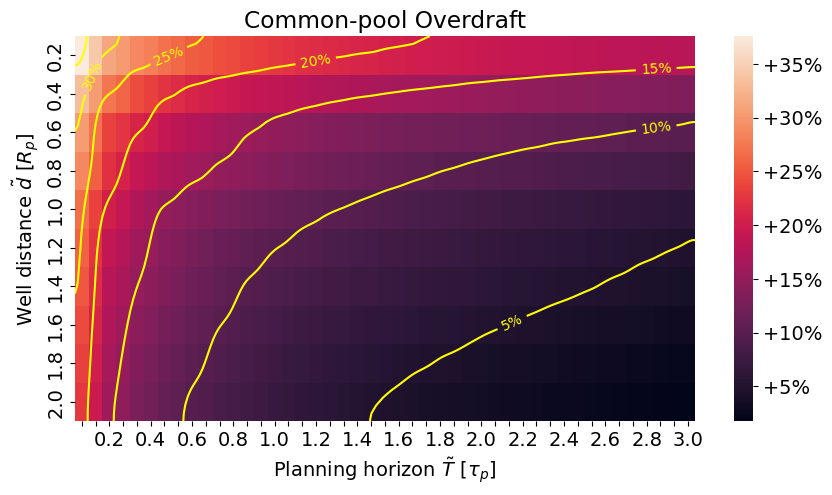

In [110]:
fig, ax = plt.subplots(figsize=(10,5))

smooth_scale = 5
z = ndimage.zoom(RHG_infinite_divergence*100, smooth_scale)
cntr = ax.contour(np.linspace(0, RHG_infinite_divergence.shape[1], RHG_infinite_divergence.shape[1] * smooth_scale),
                  np.linspace(0, RHG_infinite_divergence.shape[0], RHG_infinite_divergence.shape[0] * smooth_scale),
                  z, levels=(5, 10, 15, 20, 25, 30, 35, 40), colors='yellow')

h_ticks = [(h/param_data['dimensions']['tau_p']).round(2) if i%3==2 else "" for i, h in enumerate(horizons)]
ax = seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=h_ticks, yticklabels=distances.round(1),
                cbar_kws={'format': '+%.0f%%'})

cntr.clabel(fmt='%1.0f%%', fontsize=10, colors='yellow')

plt.title("Common-pool Overdraft")
plt.xlabel(r"Planning horizon $\tilde T$ [$\tau_p$]")
plt.ylabel(r"Well distance $\tilde d$ [$R_p$]")

# plt.savefig('../../Paper/figures/Fig4_alt.svg', format='svg')
plt.show()

In [106]:
RHG_infinite_divergence.min(), RHG_infinite_divergence.max()

(np.float64(0.01773199425252711), np.float64(0.3757818248193084))

In [104]:
RHG_infinite_divergence[0,-1], RHG_infinite_divergence[0,-16], RHG_infinite_divergence[-1,0]

(np.float64(0.17983521571605138),
 np.float64(0.1944614017477173),
 np.float64(0.22742400539122798))

In [114]:
RHG_infinite_divergence[0,0], RHG_infinite_divergence[0,14]

(np.float64(0.3757818248193084), np.float64(0.22696152762543004))

In [119]:
RHG_infinite_divergence[-1,0], RHG_infinite_divergence[-1,8], RHG_infinite_divergence[-1,20], RHG_infinite_divergence[-1,-1]

(np.float64(0.22742400539122798),
 np.float64(0.09772091935792744),
 np.float64(0.05230269815130993),
 np.float64(0.01773199425252711))